In [77]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root.
possible_roots = [
    Path.cwd(),
    *Path.cwd().parents
]

ROOT = next(
    (path for path in possible_roots if path.name == "Capstone_1"),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the Capstone_1 project folder. "
        "Please check the notebook's working directory."
    )

CLEAN_CSV = (
    ROOT
    / "Part_2"
    / "data"
    / "clean"
    / "tesla_deaths_clean.csv"
)

if not CLEAN_CSV.exists():
    raise FileNotFoundError(f"Cleaned dataset not found: {CLEAN_CSV}")

df = pd.read_csv(CLEAN_CSV)

# Parse the event date after loading the CSV.
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Project root:", ROOT)
print("Dataset path:", CLEAN_CSV)
print("Dataset shape:", df.shape)

display(df.head())

Project root: c:\Material\Repo\Projects\Capstone_1
Dataset path: c:\Material\Repo\Projects\Capstone_1\Part_2\data\clean\tesla_deaths_clean.csv
Dataset shape: (294, 33)


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,...,Deceased 4,Date_original,Year_numeric,Deaths_numeric,Date_year,Year_original,Event_year,Year_source_numeric,Year_review_flag,Year_anomaly_flag
0,294,2022.0,2023-01-17,USA,CA,Tesla crashes into back of semi,1.0,1,-,-,...,NaN,1/17/2023,2022.0,1.0,2023,2022.0,2023,2022.0,True,False
1,293,2022.0,2023-01-07,Canada,-,Tesla crashes,1.0,1,-,-,...,NaN,1/7/2023,2022.0,1.0,2023,2022.0,2023,2022.0,True,False
2,292,2022.0,2023-01-07,USA,WA,"Tesla hits pole, catches on fire",1.0,-,1,-,...,NaN,1/7/2023,2022.0,1.0,2023,2022.0,2023,2022.0,True,False
3,291,2022.0,2022-12-22,USA,GA,Tesla crashes and burns,1.0,1,-,-,...,NaN,12/22/2022,2022.0,1.0,2022,2022.0,2022,2022.0,False,False
4,290,2022.0,2022-12-19,Canada,-,Tesla crashes into storefront,1.0,-,-,-,...,NaN,12/19/2022,2022.0,1.0,2022,2022.0,2022,2022.0,False,False


In [78]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
display(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing values")
)

Column names:
['Case #', 'Year', 'Date', 'Country', 'State', 'Description', 'Deaths', 'Tesla driver', 'Tesla occupant', 'Other vehicle', 'Cyclists/ Peds', 'TSLA+cycl / peds', 'Model', 'Autopilot claimed', 'Verified Tesla Autopilot Deaths', 'Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO', 'Source_URL_1', 'Source_URL_2', 'Source', 'Note', 'Deceased 1', 'Deceased 2', 'Deceased 3', 'Deceased 4', 'Date_original', 'Year_numeric', 'Deaths_numeric', 'Date_year', 'Year_original', 'Event_year', 'Year_source_numeric', 'Year_review_flag', 'Year_anomaly_flag']

Data types:


,Data type
Case #,int64
Year,float64
Date,datetime64[us]
Country,str
State,str
Description,str
Deaths,float64
Tesla driver,str
Tesla occupant,str
Other vehicle,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 294 entries, 0 to 293
Data columns (total 33 columns):
 #   Column                                                              Non-Null Count  Dtype         
---  ------                                                              --------------  -----         
 0   Case #                                                              294 non-null    int64         
 1   Year                                                                294 non-null    float64       
 2   Date                                                                294 non-null    datetime64[us]
 3   Country                                                             294 non-null    str           
 4   State                                                               294 non-null    str           
 5   Description                                                         294 non-null    str           
 6   Deaths                                         

,Missing values
Deceased 4,294
Deceased 3,290
Note,285
Deceased 2,277
Deceased 1,207
Autopilot claimed,18
Tesla occupant,9
Source_URL_2,5
Source_URL_1,5
Tesla driver,5


In [79]:
numeric_columns = [
    "Case #",
    "Year",
    "Event_year",
    "Deaths",
    "Tesla driver",
    "Tesla occupant",
    "Other vehicle",
    "Cyclists/ Peds",
    "TSLA+cycl / peds",
    "Verified Tesla Autopilot Deaths",
    "Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO"
]

# Keep only columns that are present in the dataset.
numeric_columns = [
    col for col in numeric_columns if col in df.columns
]

# Create numeric analysis copies; original columns remain unchanged.
numeric_df = df[numeric_columns].copy()

for col in numeric_columns:
    numeric_df[col] = pd.to_numeric(
        numeric_df[col].replace("-", np.nan),
        errors="coerce"
    )

display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Case #,294.0,147.500000,85.014705,1.0,74.25,147.5,220.75,294.0
Year,294.0,2013.850340,106.050207,202.0,2019.00,2021.0,2022.00,2022.0
Event_year,294.0,2020.051020,2.090311,2013.0,2019.00,2021.0,2022.00,2023.0
Deaths,294.0,1.200680,0.513171,1.0,1.00,1.0,1.00,4.0
Tesla driver,117.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
Tesla occupant,43.0,1.116279,0.390927,1.0,1.00,1.0,1.00,3.0
Other vehicle,110.0,1.181818,0.510115,1.0,1.00,1.0,1.00,4.0
Cyclists/ Peds,44.0,1.045455,0.210707,1.0,1.00,1.0,1.00,2.0
TSLA+cycl / peds,181.0,1.160221,0.449404,1.0,1.00,1.0,1.00,4.0
Verified Tesla Autopilot Deaths,16.0,1.187500,0.403113,1.0,1.00,1.0,1.00,2.0


,Recorded incidents
Event_year,
2013,2
2014,4
2015,5
2016,15
2017,11
2018,18
2019,46
2020,39
2021,58


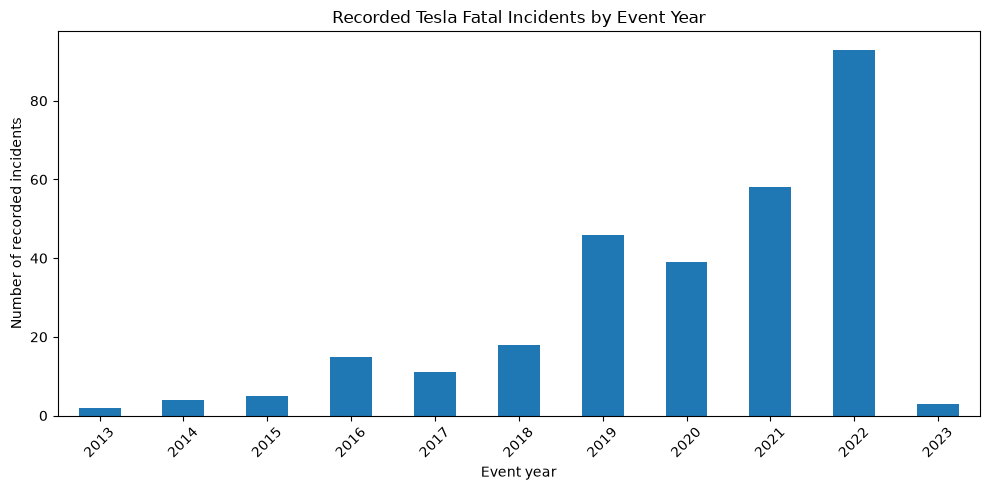

In [80]:
# Count recorded incidents by calendar year from the event date.
incidents_by_year = (
    df.groupby("Event_year")
      .size()
      .sort_index()
)

display(incidents_by_year.to_frame("Recorded incidents"))

plt.figure(figsize=(10, 5))
incidents_by_year.plot(kind="bar")

plt.title("Recorded Tesla Fatal Incidents by Event Year")
plt.xlabel("Event year")
plt.ylabel("Number of recorded incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Recorded deaths
Event_year,
2013,3.0
2014,6.0
2015,5.0
2016,16.0
2017,11.0
2018,21.0
2019,50.0
2020,47.0
2021,75.0


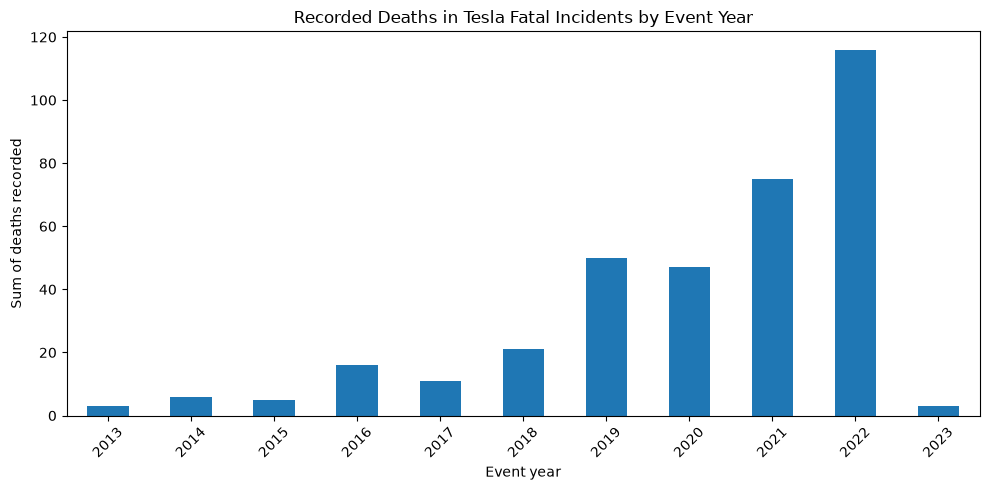

In [81]:
deaths_by_year = (
    df.groupby("Event_year")["Deaths"]
      .sum()
      .sort_index()
)

display(deaths_by_year.to_frame("Recorded deaths"))

plt.figure(figsize=(10, 5))
deaths_by_year.plot(kind="bar")

plt.title("Recorded Deaths in Tesla Fatal Incidents by Event Year")
plt.xlabel("Event year")
plt.ylabel("Sum of deaths recorded")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Number of incidents
Deaths,
1.0,247
2.0,38
3.0,6
4.0,3


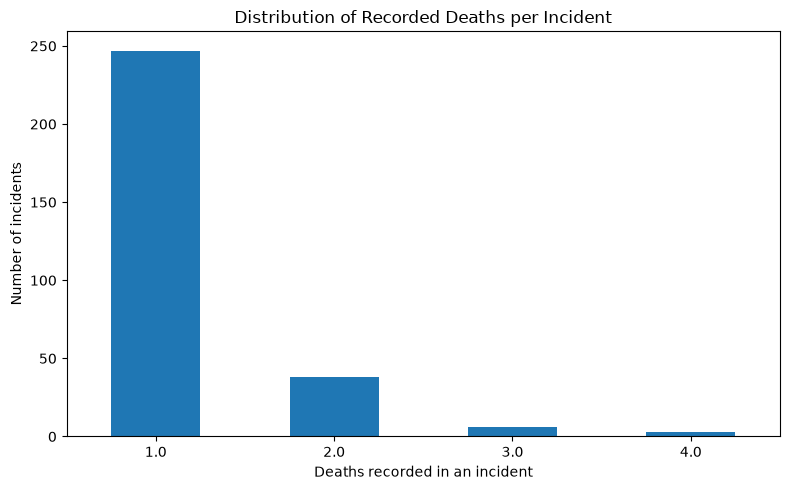

In [82]:
deaths_distribution = (
    df["Deaths"]
      .value_counts()
      .sort_index()
)

display(deaths_distribution.to_frame("Number of incidents"))

plt.figure(figsize=(8, 5))
deaths_distribution.plot(kind="bar")

plt.title("Distribution of Recorded Deaths per Incident")
plt.xlabel("Deaths recorded in an incident")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Recorded incidents
Country,
USA,215
China,16
Germany,11
Canada,10
Netherlands,6
UK,5
Norway,4
Switzerland,3
Taiwan,3


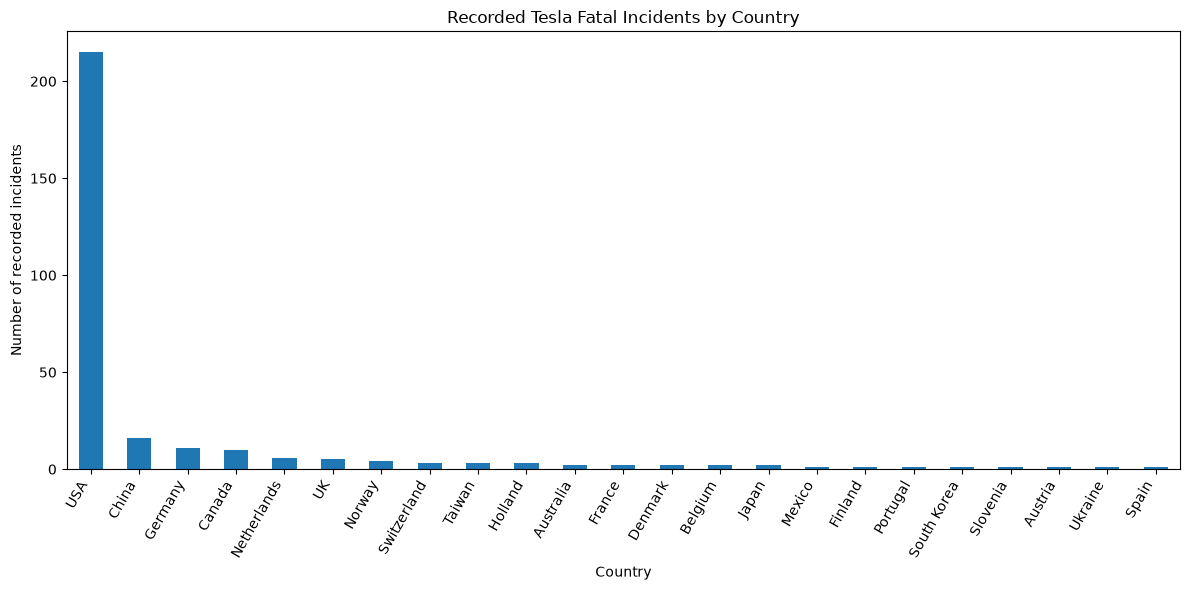

In [83]:
# Normalize whitespace for grouping, without changing the source dataset.
country_clean = (
    df["Country"]
      .astype("string")
      .str.strip()
      .replace("", pd.NA)
)

incidents_by_country = (
    country_clean
      .value_counts(dropna=False)
      .rename_axis("Country")
      .to_frame("Recorded incidents")
)

display(incidents_by_country)

plt.figure(figsize=(12, 6))
incidents_by_country["Recorded incidents"].plot(kind="bar")

plt.title("Recorded Tesla Fatal Incidents by Country")
plt.xlabel("Country")
plt.ylabel("Number of recorded incidents")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

,Recorded incidents
State,
CA,91
FL,32
GA,9
AZ,8
PA,7
NY,6
OH,6
UT,5
MO,4


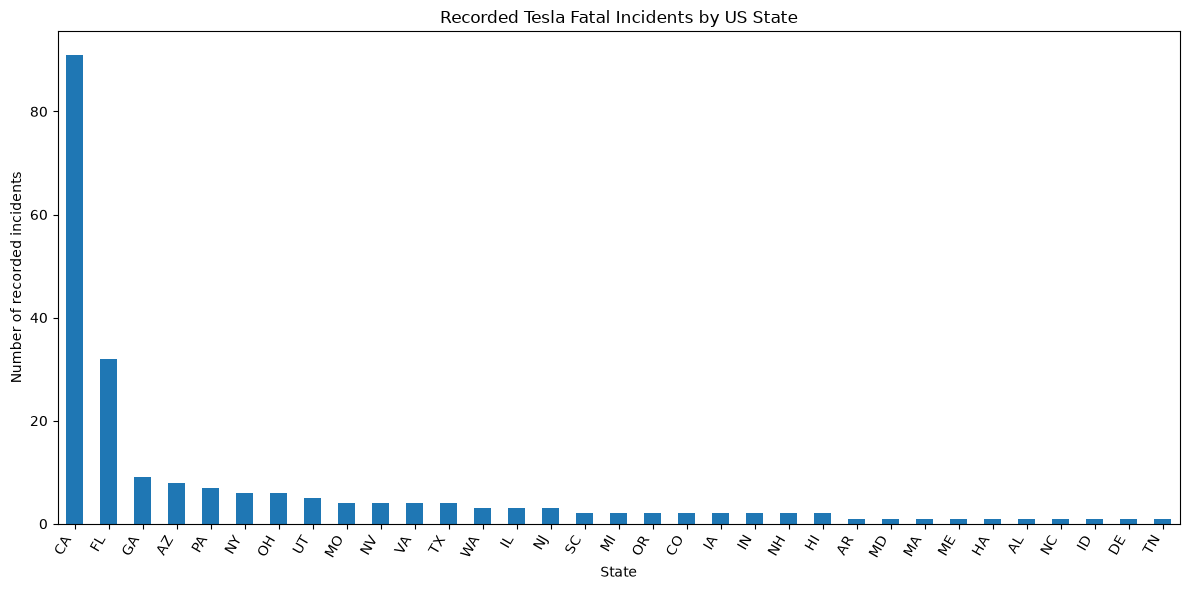

In [84]:
usa_df = df.loc[
    df["Country"].astype("string").str.strip().str.upper().eq("USA")
].copy()

usa_df["State_clean"] = (
    usa_df["State"]
      .astype("string")
      .str.strip()
      .replace("", pd.NA)
      .fillna("Not specified")
      .replace("-", "Not specified")
)

incidents_by_state = (
    usa_df["State_clean"]
      .value_counts()
      .rename_axis("State")
      .to_frame("Recorded incidents")
)

display(incidents_by_state)

plt.figure(figsize=(12, 6))
incidents_by_state["Recorded incidents"].plot(kind="bar")

plt.title("Recorded Tesla Fatal Incidents by US State")
plt.xlabel("State")
plt.ylabel("Number of recorded incidents")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [85]:
involvement_columns = [
    "Tesla driver",
    "Tesla occupant",
    "Other vehicle",
    "Cyclists/ Peds",
    "TSLA+cycl / peds",
    "Model",
    "Autopilot claimed",
    "Verified Tesla Autopilot Deaths"
]

for col in involvement_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).to_string())


--- Tesla driver ---
Tesla driver
 -      172
  1     117
NaN       5

--- Tesla occupant ---
Tesla occupant
 -      242
  1      39
NaN       9
  2       3
  3       1

--- Other vehicle ---
Other vehicle
 -      180
  1      95
  2      11
NaN       4
  3       3
  4       1

--- Cyclists/ Peds ---
Cyclists/ Peds
 -      247
  1      42
NaN       3
  2       2

--- TSLA+cycl / peds ---
TSLA+cycl / peds
  1     157
 -      111
  2      20
  3       3
NaN       2
  4       1

--- Model ---
Model
-      181
S       45
 3      39
X       17
Y       10
 1       1
 2       1

--- Autopilot claimed ---
Autopilot claimed
 -      241
  1      32
NaN      18
  2       3

--- Verified Tesla Autopilot Deaths ---
Verified Tesla Autopilot Deaths
 -      273
  1      13
NaN       4
  2       3
-         1


In [86]:
involvement_df = df.copy()

text_columns = [
    "Country",
    "State",
    "Tesla driver",
    "Tesla occupant",
    "Other vehicle",
    "Cyclists/ Peds",
    "TSLA+cycl / peds",
    "Model",
    "Autopilot claimed",
    "Verified Tesla Autopilot Deaths",
    "Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO"
]

for col in text_columns:
    if col in involvement_df.columns:
        involvement_df[col] = (
            involvement_df[col]
            .astype("string")
            .str.strip()
            .replace({
                "": pd.NA, #type: ignore
                "-": pd.NA
            })
        )

print("Text markers standardized in the analysis copy.")
print("Original df remains unchanged.")

Text markers standardized in the analysis copy.
Original df remains unchanged.


In [87]:
count_columns = [
    "Tesla driver",
    "Tesla occupant",
    "Other vehicle",
    "Cyclists/ Peds",
    "TSLA+cycl / peds",
    "Verified Tesla Autopilot Deaths",
    "Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO"
]

for col in count_columns:
    if col in involvement_df.columns:
        involvement_df[col + "_count"] = pd.to_numeric(
            involvement_df[col],
            errors="coerce"
        )

count_analysis_columns = [
    col + "_count"
    for col in count_columns
    if col in involvement_df.columns
]

display(involvement_df[count_analysis_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Tesla driver_count,117.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Tesla occupant_count,43.0,1.116279,0.390927,1.0,1.0,1.0,1.0,3.0
Other vehicle_count,110.0,1.181818,0.510115,1.0,1.0,1.0,1.0,4.0
Cyclists/ Peds_count,44.0,1.045455,0.210707,1.0,1.0,1.0,1.0,2.0
TSLA+cycl / peds_count,181.0,1.160221,0.449404,1.0,1.0,1.0,1.0,4.0
Verified Tesla Autopilot Deaths_count,16.0,1.1875,0.403113,1.0,1.0,1.0,1.0,2.0
Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO_count,24.0,1.125,0.337832,1.0,1.0,1.0,1.0,2.0


In [88]:
involvement_summary = []

for col in count_columns:
    count_col = col + "_count"

    if count_col not in involvement_df.columns:
        continue

    values = involvement_df[count_col]

    involvement_summary.append({
        "Field": col,
        "Records with recorded value": int(values.notna().sum()),
        "Records with positive value": int((values > 0).sum()),
        "Unknown / unrecorded": int(values.isna().sum())
    })

involvement_summary_df = pd.DataFrame(involvement_summary)

display(involvement_summary_df)

,Field,Records with recorded value,Records with positive value,Unknown / unrecorded
0,Tesla driver,117,117,177
1,Tesla occupant,43,43,251
2,Other vehicle,110,110,184
3,Cyclists/ Peds,44,44,250
4,TSLA+cycl / peds,181,181,113
5,Verified Tesla Autopilot Deaths,16,16,278
6,Verified Tesla Autopilot Deaths + All Deaths R...,24,24,270


,Records with positive recorded value
Tesla driver,117
Tesla occupant,43


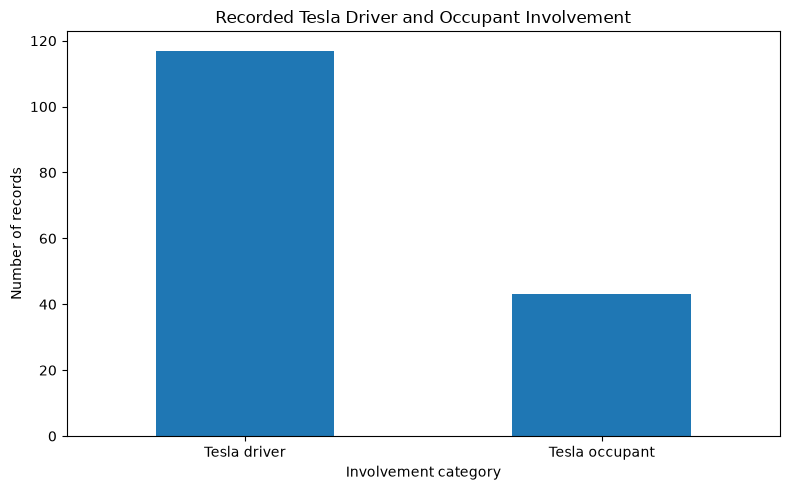

In [89]:
driver_col = "Tesla driver_count"
occupant_col = "Tesla occupant_count"

driver_occupant_summary = pd.Series({
    "Tesla driver": int((involvement_df[driver_col] > 0).sum()),
    "Tesla occupant": int((involvement_df[occupant_col] > 0).sum())
})

display(driver_occupant_summary.to_frame("Records with positive recorded value"))

plt.figure(figsize=(8, 5))
driver_occupant_summary.plot(kind="bar")

plt.title("Recorded Tesla Driver and Occupant Involvement")
plt.xlabel("Involvement category")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Records with positive recorded value
Other vehicle,110
Cyclists / pedestrians,44


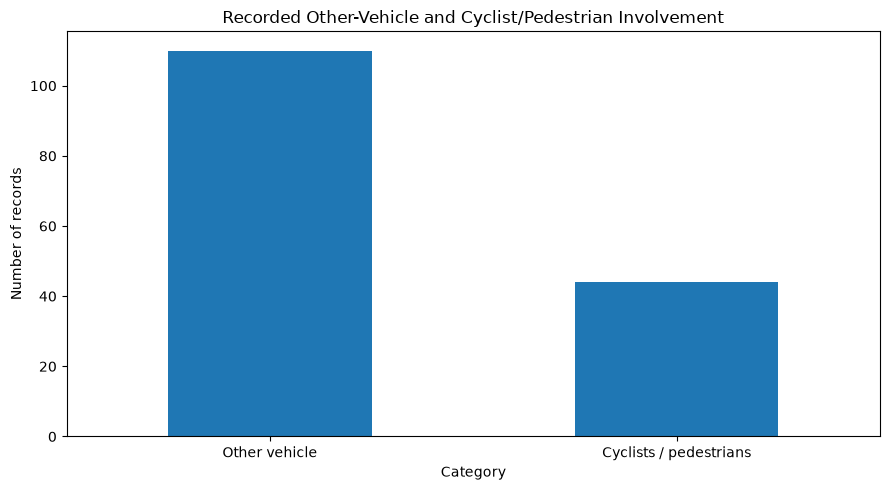

In [90]:
other_road_user_summary = pd.Series({
    "Other vehicle": int((involvement_df["Other vehicle_count"] > 0).sum()),
    "Cyclists / pedestrians": int((involvement_df["Cyclists/ Peds_count"] > 0).sum())
})

display(other_road_user_summary.to_frame("Records with positive recorded value"))

plt.figure(figsize=(9, 5))
other_road_user_summary.plot(kind="bar")

plt.title("Recorded Other-Vehicle and Cyclist/Pedestrian Involvement")
plt.xlabel("Category")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Recorded incidents
Model category,
<NA>,181
S,45
3,39
X,17
Y,10
1,1
2,1


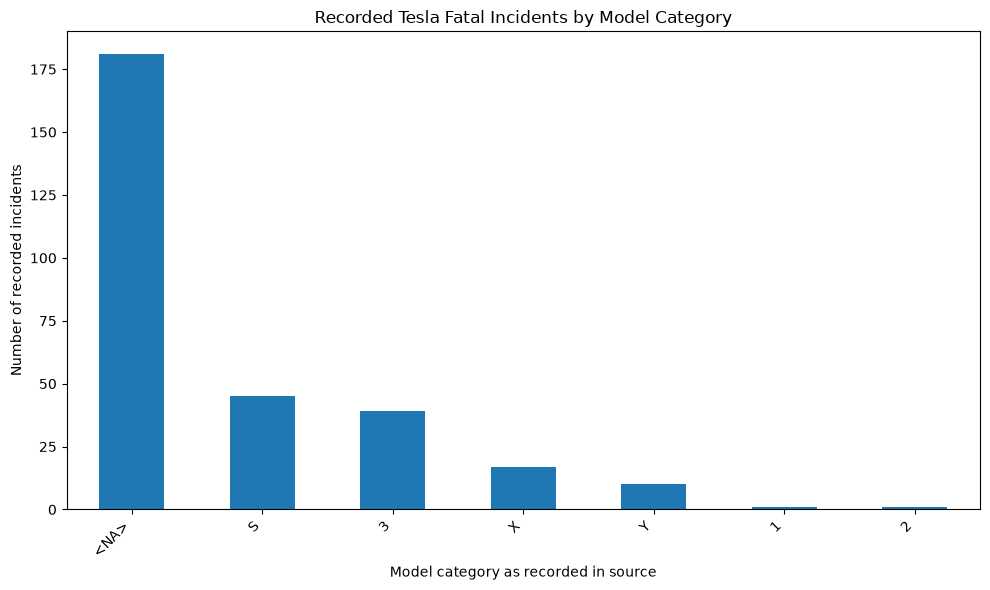

In [91]:
model_counts = (
    involvement_df["Model"]
    .value_counts(dropna=False)
    .rename_axis("Model category")
    .to_frame("Recorded incidents")
)

display(model_counts)

plt.figure(figsize=(10, 6))
model_counts["Recorded incidents"].plot(kind="bar")

plt.title("Recorded Tesla Fatal Incidents by Model Category")
plt.xlabel("Model category as recorded in source")
plt.ylabel("Number of recorded incidents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [92]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root
ROOT = Path.cwd()

while ROOT.name != "Capstone_1" and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if ROOT.name != "Capstone_1":
    raise FileNotFoundError(
        "Could not locate the Capstone_1 project root. "
        "Run this notebook from within the project directory."
    )

DATA_PATH = (
    ROOT
    / "Part_2"
    / "data"
    / "clean"
    / "tesla_deaths_analysis_ready.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Unique case numbers:", df["Case #"].nunique())

display(df.head())


Dataset loaded successfully.
Shape: (294, 41)
Date range: 2013-04-02 00:00:00 to 2023-01-17 00:00:00
Unique case numbers: 294


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,...,Year_review_flag,Year_anomaly_flag,Deaths_count,Tesla driver_count,Tesla occupant_count,Other vehicle_count,Cyclists/ Peds_count,TSLA+cycl / peds_count,Verified Tesla Autopilot Deaths_count,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO_count
0,294,2022.0,2023-01-17,USA,CA,Tesla crashes into back of semi,1.0,1.0,NaN,NaN,...,True,False,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN
1,293,2022.0,2023-01-07,Canada,NaN,Tesla crashes,1.0,1.0,NaN,NaN,...,True,False,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN
2,292,2022.0,2023-01-07,USA,WA,"Tesla hits pole, catches on fire",1.0,NaN,1.0,NaN,...,True,False,1.0,NaN,1.0,NaN,NaN,1.0,NaN,NaN
3,291,2022.0,2022-12-22,USA,GA,Tesla crashes and burns,1.0,1.0,NaN,NaN,...,False,False,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN
4,290,2022.0,2022-12-19,Canada,NaN,Tesla crashes into storefront,1.0,NaN,NaN,NaN,...,False,False,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN


In [93]:

required_columns = [
    "Case #",
    "Date",
    "Event_year",
    "Country",
    "State",
    "Description",
    "Deaths",
    "Tesla driver_count",
    "Tesla occupant_count",
    "Other vehicle_count",
    "Cyclists/ Peds_count",
    "TSLA+cycl / peds_count",
    "Model",
    "Autopilot claimed",
    "Verified Tesla Autopilot Deaths_count",
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    print("Missing expected columns:")
    print(missing_columns)
else:
    print("All expected EDA columns are present.")

display(df[required_columns].head())


All expected EDA columns are present.


,Case #,Date,Event_year,Country,State,Description,Deaths,Tesla driver_count,Tesla occupant_count,Other vehicle_count,Cyclists/ Peds_count,TSLA+cycl / peds_count,Model,Autopilot claimed,Verified Tesla Autopilot Deaths_count
0,294,2023-01-17,2023,USA,CA,Tesla crashes into back of semi,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN
1,293,2023-01-07,2023,Canada,NaN,Tesla crashes,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN
2,292,2023-01-07,2023,USA,WA,"Tesla hits pole, catches on fire",1.0,NaN,1.0,NaN,NaN,1.0,NaN,NaN,NaN
3,291,2022-12-22,2022,USA,GA,Tesla crashes and burns,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN
4,290,2022-12-19,2022,Canada,NaN,Tesla crashes into storefront,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN


,Recorded_Incidents,Recorded_Deaths
Event_year,,
2013,2,3.0
2014,4,6.0
2015,5,5.0
2016,15,16.0
2017,11,11.0
2018,18,21.0
2019,46,50.0
2020,39,47.0
2021,58,75.0


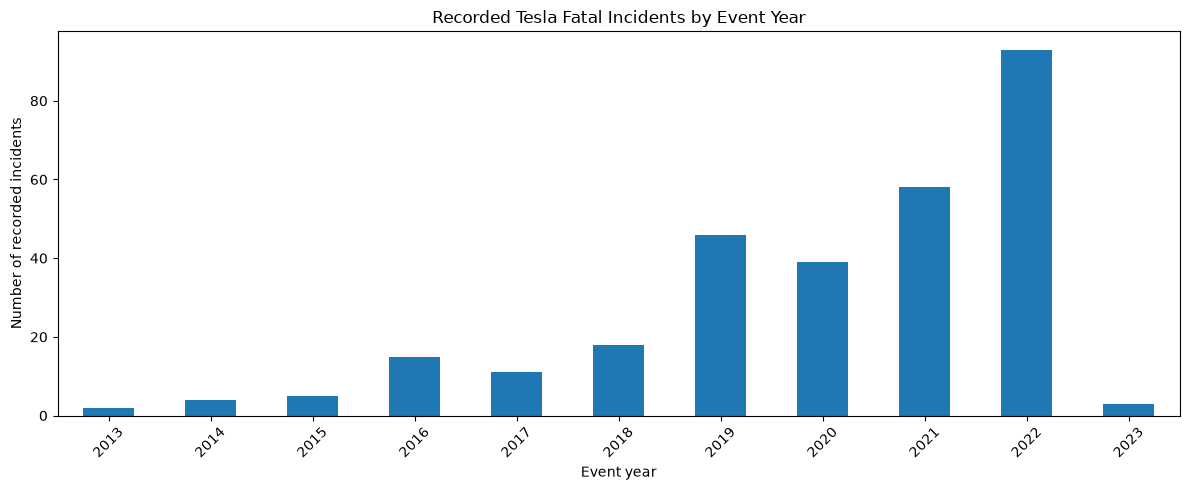

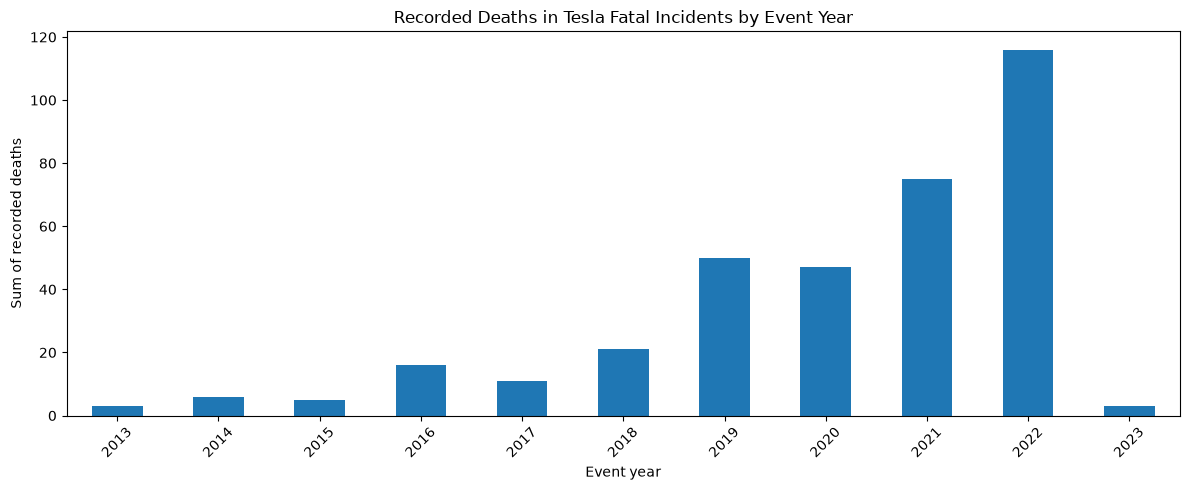

In [94]:

# Annual incident and death totals
annual_summary = (
    df.groupby("Event_year")
      .agg(
          Recorded_Incidents=("Case #", "count"),
          Recorded_Deaths=("Deaths_count", "sum")
      )
      .sort_index()
)

display(annual_summary)

# Plot 1: Annual incident counts
plt.figure(figsize=(12, 5))
annual_summary["Recorded_Incidents"].plot(kind="bar")
plt.title("Recorded Tesla Fatal Incidents by Event Year")
plt.xlabel("Event year")
plt.ylabel("Number of recorded incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Annual recorded deaths
plt.figure(figsize=(12, 5))
annual_summary["Recorded_Deaths"].plot(kind="bar")
plt.title("Recorded Deaths in Tesla Fatal Incidents by Event Year")
plt.xlabel("Event year")
plt.ylabel("Sum of recorded deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Number_of_Incidents
Deaths_per_Incident,
1.0,247
2.0,38
3.0,6
4.0,3


Total recorded incidents: 294
Total recorded deaths: 353
Mean deaths per incident: 1.201
Median deaths per incident: 1.0
Maximum deaths in a single recorded incident: 4


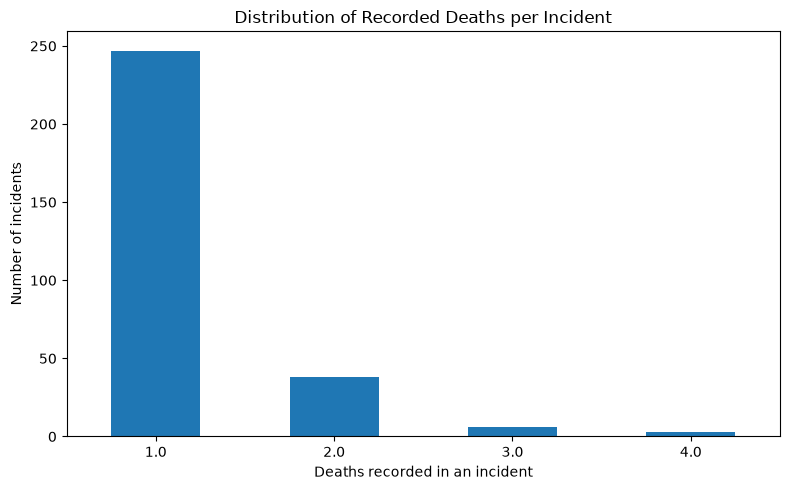

In [95]:

# Frequency of incidents by recorded death count
deaths_distribution = (
    df["Deaths_count"]
      .value_counts()
      .sort_index()
      .rename_axis("Deaths_per_Incident")
      .to_frame("Number_of_Incidents")
)

display(deaths_distribution)

# Summary statistics
print("Total recorded incidents:", len(df))
print("Total recorded deaths:", int(df["Deaths_count"].sum()))
print("Mean deaths per incident:", round(df["Deaths_count"].mean(), 3))
print("Median deaths per incident:", df["Deaths_count"].median())
print("Maximum deaths in a single recorded incident:", int(df["Deaths_count"].max()))

# Visualization
plt.figure(figsize=(8, 5))
deaths_distribution["Number_of_Incidents"].plot(kind="bar")
plt.title("Distribution of Recorded Deaths per Incident")
plt.xlabel("Deaths recorded in an incident")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Recorded_Incidents
Event_month,
1,21
2,9
3,24
4,23
5,28
6,28
7,27
8,24
9,26


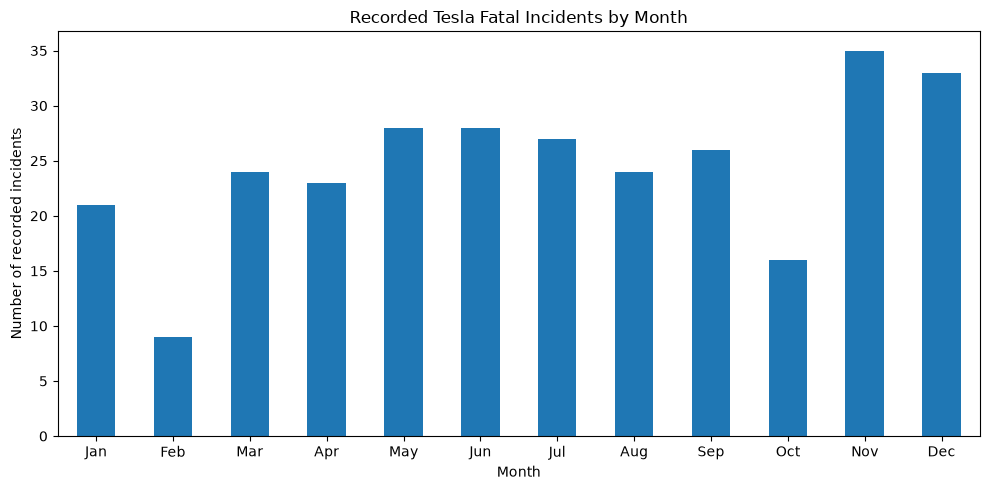

,Recorded_Incidents
Event_weekday_name,
Monday,43
Tuesday,35
Wednesday,41
Thursday,28
Friday,45
Saturday,53
Sunday,49


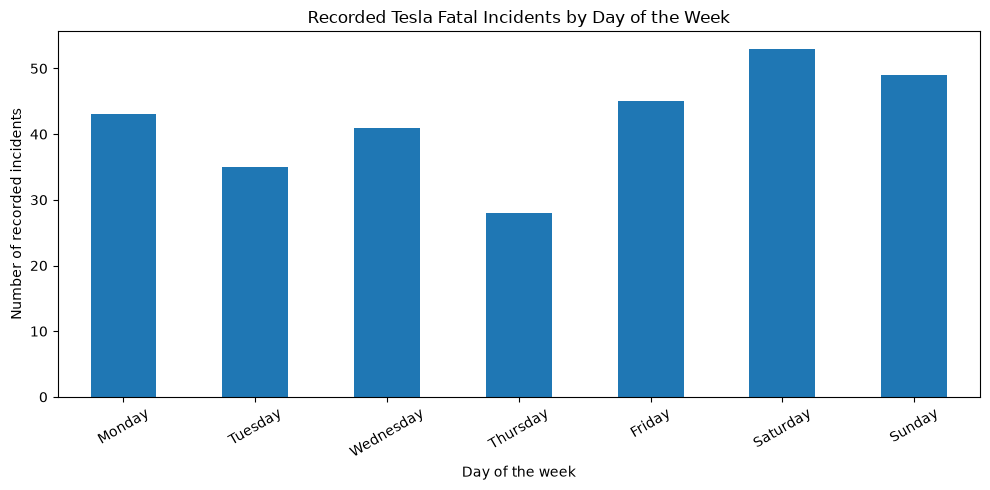

In [96]:

# Derive calendar features from the parsed event date
df["Event_month"] = df["Date"].dt.month
df["Event_month_name"] = df["Date"].dt.month_name()
df["Event_weekday"] = df["Date"].dt.dayofweek
df["Event_weekday_name"] = df["Date"].dt.day_name()

# Month distribution in calendar order
monthly_summary = (
    df.groupby("Event_month")
      .size()
      .reindex(range(1, 13), fill_value=0)
      .rename("Recorded_Incidents")
      .to_frame()
)

display(monthly_summary)

plt.figure(figsize=(10, 5))
monthly_summary["Recorded_Incidents"].plot(kind="bar")
plt.title("Recorded Tesla Fatal Incidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of recorded incidents")
plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
plt.tight_layout()
plt.show()

# Weekday distribution in Monday-to-Sunday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df["Event_weekday_name"]
      .value_counts()
      .reindex(weekday_order, fill_value=0)
      .rename("Recorded_Incidents")
      .to_frame()
)

display(weekday_summary)

plt.figure(figsize=(10, 5))
weekday_summary["Recorded_Incidents"].plot(kind="bar")
plt.title("Recorded Tesla Fatal Incidents by Day of the Week")
plt.xlabel("Day of the week")
plt.ylabel("Number of recorded incidents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [97]:

from pathlib import Path

# Your project directory
ROOT = Path(r"C:\Material\Repo\Projects\Capstone\_1")

clean_dir = ROOT / "Part_2" / "data" / "clean"

print("Project directory exists:", ROOT.exists())
print("Clean data directory exists:", clean_dir.exists())

if clean_dir.exists():
    print("\nCSV files found under the clean data directory:")
    csv_files = sorted(clean_dir.rglob("*.csv"))

    if csv_files:
        for file_path in csv_files:
            print(file_path)
    else:
        print("No CSV files found.")
else:
    print("Check the project directory and folder names.")


Project directory exists: False
Clean data directory exists: False
Check the project directory and folder names.


In [98]:

# Replace this with the exact path printed in Step 1
ANALYSIS_READY_PATH = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_2\data\clean\tesla_deaths_analysis_ready.csv"
)
tesla_df = pd.read_csv(ANALYSIS_READY_PATH)
tesla_df["Date"] = pd.to_datetime(tesla_df["Date"], errors="coerce")

print("Variable type:", type(tesla_df))
print("Dataset shape:", tesla_df.shape)

display(tesla_df.head())


Variable type: <class 'pandas.DataFrame'>
Dataset shape: (294, 41)


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,...,Year_review_flag,Year_anomaly_flag,Deaths_count,Tesla driver_count,Tesla occupant_count,Other vehicle_count,Cyclists/ Peds_count,TSLA+cycl / peds_count,Verified Tesla Autopilot Deaths_count,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO_count
0,294,2022.0,2023-01-17,USA,CA,Tesla crashes into back of semi,1.0,1.0,NaN,NaN,...,True,False,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN
1,293,2022.0,2023-01-07,Canada,NaN,Tesla crashes,1.0,1.0,NaN,NaN,...,True,False,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN
2,292,2022.0,2023-01-07,USA,WA,"Tesla hits pole, catches on fire",1.0,NaN,1.0,NaN,...,True,False,1.0,NaN,1.0,NaN,NaN,1.0,NaN,NaN
3,291,2022.0,2022-12-22,USA,GA,Tesla crashes and burns,1.0,1.0,NaN,NaN,...,False,False,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN
4,290,2022.0,2022-12-19,Canada,NaN,Tesla crashes into storefront,1.0,NaN,NaN,NaN,...,False,False,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN


In [99]:
import pandas as pd
from pathlib import Path

ANALYSIS_READY_PATH = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_2\data\clean\tesla_deaths_analysis_ready.csv"
)

print("Dataset exists:", ANALYSIS_READY_PATH.exists())
print("Dataset path:", ANALYSIS_READY_PATH)

if not ANALYSIS_READY_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{ANALYSIS_READY_PATH}"
    )

tesla_df = pd.read_csv(ANALYSIS_READY_PATH)

print("\nDataset loaded successfully!")
print("Shape:", tesla_df.shape)
print("Columns:", len(tesla_df.columns))

Dataset exists: True
Dataset path: C:\Material\Repo\Projects\Capstone_1\Part_2\data\clean\tesla_deaths_analysis_ready.csv

Dataset loaded successfully!
Shape: (294, 41)
Columns: 41


In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

eda_df = tesla_df.copy()

# Numeric versions of the recorded count fields.
count_fields = [
    "Deaths",
    "Tesla driver",
    "Tesla occupant",
    "Other vehicle",
    "Cyclists/ Peds",
    "TSLA+cycl / peds",
    "Verified Tesla Autopilot Deaths",
    "Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO"
]

for col in count_fields:
    if col in eda_df.columns:
        eda_df[col + "_count"] = pd.to_numeric(
            eda_df[col], errors="coerce"
        )

# Normalize Autopilot claimed into a numeric analysis field.
eda_df["Autopilot_claimed_count"] = pd.to_numeric(
    eda_df["Autopilot claimed"], errors="coerce"
)

print("Working analysis copy:", eda_df.shape)
print("Unique cases:", eda_df["Case #"].nunique())

Working analysis copy: (294, 42)
Unique cases: 294


In [101]:
print("Working analysis copy:", eda_df.shape)
print("Unique cases:", eda_df["Case #"].nunique())
print("Duplicate cases:", eda_df["Case #"].duplicated().sum())

Working analysis copy: (294, 42)
Unique cases: 294
Duplicate cases: 0


In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Work on a copy
temporal_df = eda_df.copy()

# Ensure Date is datetime
temporal_df["Date"] = pd.to_datetime(
    temporal_df["Date"],
    errors="coerce"
)

# Create temporal features
temporal_df["Event_year"] = temporal_df["Date"].dt.year
temporal_df["Event_month"] = temporal_df["Date"].dt.month
temporal_df["Event_month_name"] = temporal_df["Date"].dt.month_name()
temporal_df["Event_weekday"] = temporal_df["Date"].dt.weekday
temporal_df["Event_weekday_name"] = temporal_df["Date"].dt.day_name()

print("Temporal features created.")
print("Date range:", temporal_df["Date"].min(), "to", temporal_df["Date"].max())
print("Missing dates:", temporal_df["Date"].isna().sum())

Temporal features created.
Date range: 2013-04-02 00:00:00 to 2023-01-17 00:00:00
Missing dates: 0


In [103]:
yearly_summary = (
    temporal_df
    .groupby("Event_year")
    .agg(
        Recorded_Incidents=("Case #", "nunique"),
        Recorded_Deaths=("Deaths_count", "sum")
    )
    .reset_index()
)

print(yearly_summary.to_string(index=False))

 Event_year  Recorded_Incidents  Recorded_Deaths
       2013                   2              3.0
       2014                   4              6.0
       2015                   5              5.0
       2016                  15             16.0
       2017                  11             11.0
       2018                  18             21.0
       2019                  46             50.0
       2020                  39             47.0
       2021                  58             75.0
       2022                  93            116.0
       2023                   3              3.0


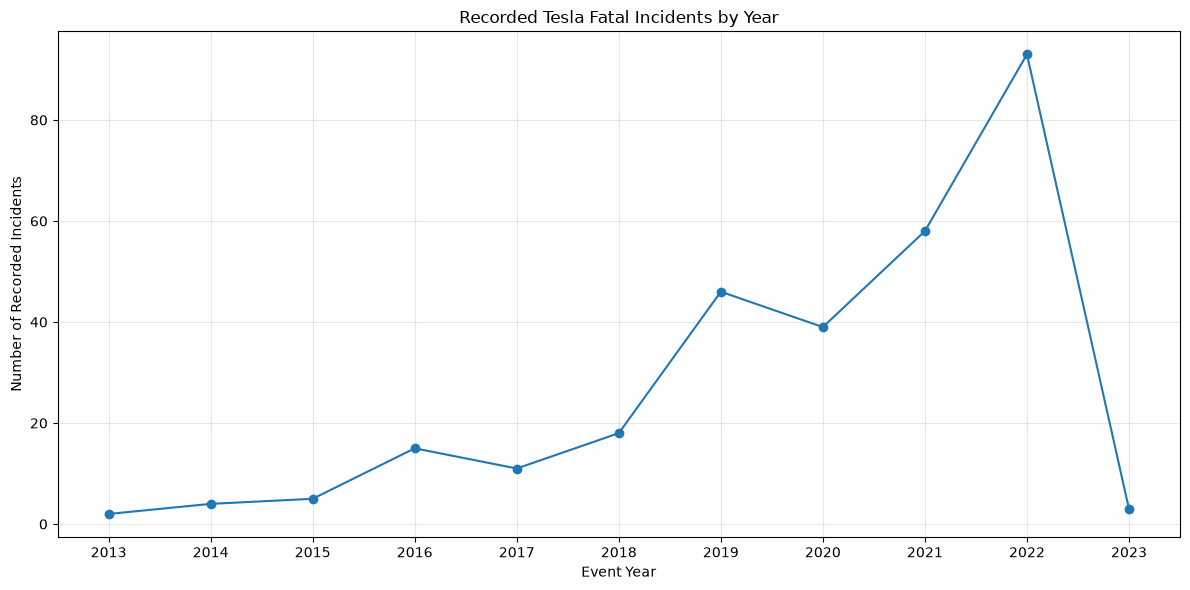

In [104]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_summary["Event_year"],
    yearly_summary["Recorded_Incidents"],
    marker="o"
)

plt.title("Recorded Tesla Fatal Incidents by Year")
plt.xlabel("Event Year")
plt.ylabel("Number of Recorded Incidents")
plt.xticks(yearly_summary["Event_year"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

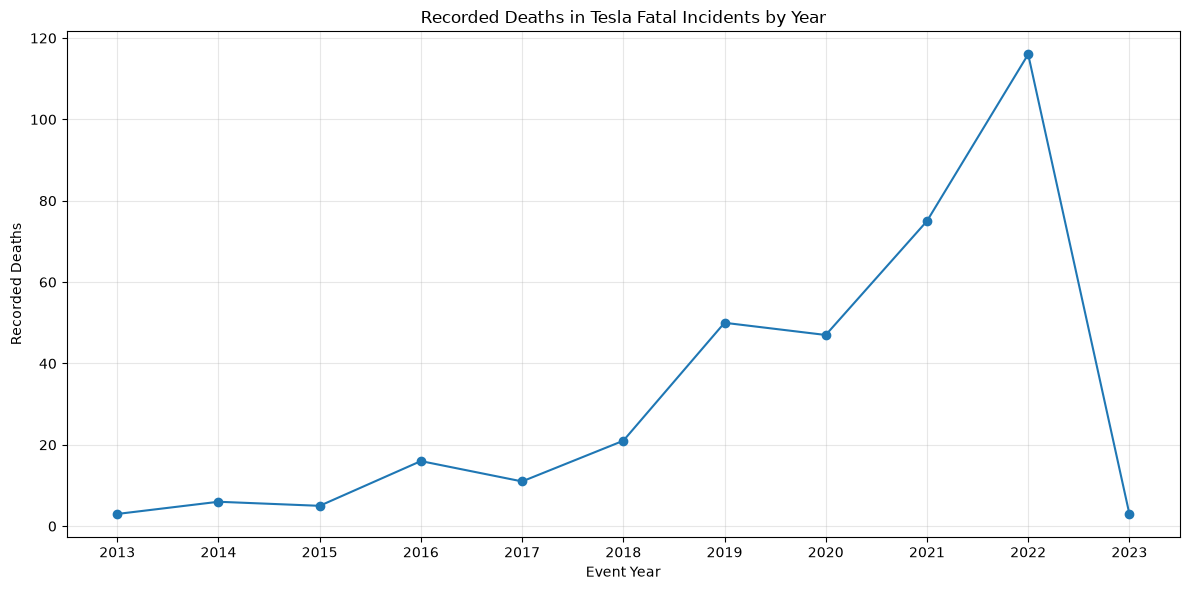

In [105]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_summary["Event_year"],
    yearly_summary["Recorded_Deaths"],
    marker="o"
)

plt.title("Recorded Deaths in Tesla Fatal Incidents by Year")
plt.xlabel("Event Year")
plt.ylabel("Recorded Deaths")
plt.xticks(yearly_summary["Event_year"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [106]:
monthly_summary = (
    temporal_df
    .groupby("Event_month")
    .agg(
        Recorded_Incidents=("Case #", "nunique"),
        Recorded_Deaths=("Deaths_count", "sum")
    )
    .reset_index()
)

month_order = list(range(1, 13))

monthly_summary = (
    monthly_summary
    .set_index("Event_month")
    .reindex(month_order)
    .reset_index()
)

print(monthly_summary.to_string(index=False))

 Event_month  Recorded_Incidents  Recorded_Deaths
           1                  21             24.0
           2                   9             11.0
           3                  24             28.0
           4                  23             27.0
           5                  28             36.0
           6                  28             34.0
           7                  27             31.0
           8                  24             35.0
           9                  26             32.0
          10                  16             19.0
          11                  35             39.0
          12                  33             37.0


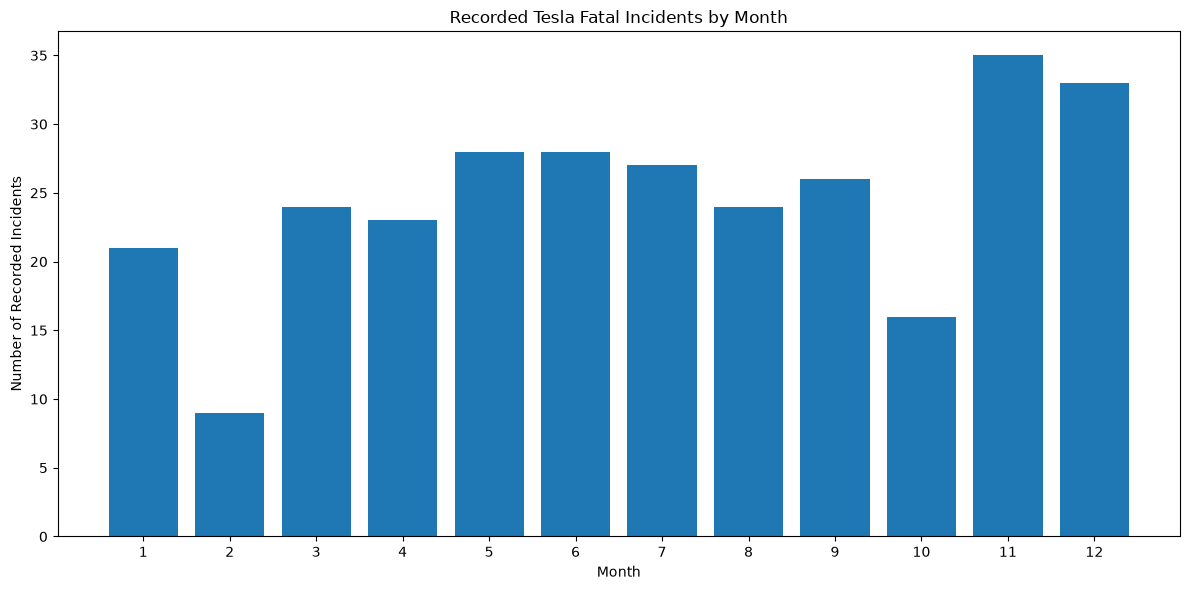

In [107]:
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_summary["Event_month"],
    monthly_summary["Recorded_Incidents"]
)

plt.title("Recorded Tesla Fatal Incidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of Recorded Incidents")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [108]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_summary = (
    temporal_df
    .groupby("Event_weekday_name")
    .agg(
        Recorded_Incidents=("Case #", "nunique"),
        Recorded_Deaths=("Deaths_count", "sum")
    )
    .reindex(weekday_order)
    .reset_index()
)

print(weekday_summary.to_string(index=False))

Event_weekday_name  Recorded_Incidents  Recorded_Deaths
            Monday                  43             49.0
           Tuesday                  35             45.0
         Wednesday                  41             51.0
          Thursday                  28             30.0
            Friday                  45             52.0
          Saturday                  53             62.0
            Sunday                  49             64.0


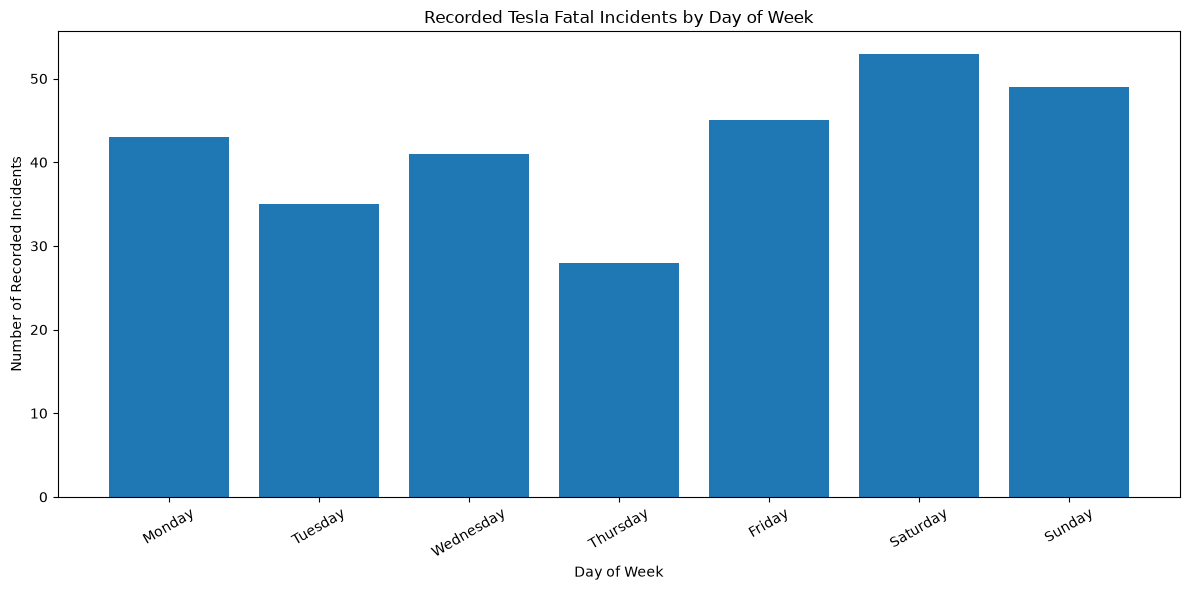

In [109]:
plt.figure(figsize=(12, 6))

plt.bar(
    weekday_summary["Event_weekday_name"],
    weekday_summary["Recorded_Incidents"]
)

plt.title("Recorded Tesla Fatal Incidents by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Recorded Incidents")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [110]:
temporal_analysis = {
    "yearly": yearly_summary,
    "monthly": monthly_summary,
    "weekday": weekday_summary
}

print("Temporal analysis completed successfully.")

print("\nYearly summary:")
display(yearly_summary)

print("\nMonthly summary:")
display(monthly_summary)

print("\nWeekday summary:")
display(weekday_summary)

Temporal analysis completed successfully.

Yearly summary:


,Event_year,Recorded_Incidents,Recorded_Deaths
0,2013,2,3.0
1,2014,4,6.0
2,2015,5,5.0
3,2016,15,16.0
4,2017,11,11.0
5,2018,18,21.0
6,2019,46,50.0
7,2020,39,47.0
8,2021,58,75.0
9,2022,93,116.0



Monthly summary:


,Event_month,Recorded_Incidents,Recorded_Deaths
0,1,21,24.0
1,2,9,11.0
2,3,24,28.0
3,4,23,27.0
4,5,28,36.0
5,6,28,34.0
6,7,27,31.0
7,8,24,35.0
8,9,26,32.0
9,10,16,19.0



Weekday summary:


,Event_weekday_name,Recorded_Incidents,Recorded_Deaths
0,Monday,43,49.0
1,Tuesday,35,45.0
2,Wednesday,41,51.0
3,Thursday,28,30.0
4,Friday,45,52.0
5,Saturday,53,62.0
6,Sunday,49,64.0


Working dataframe: (294, 42)

Autopilot-related columns found:
'Autopilot claimed'
'Verified Tesla Autopilot Deaths'
'Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO'
'Verified Tesla Autopilot Deaths_count'
'Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO_count'
'Autopilot_claimed_count'

Using Autopilot claim column:
'Autopilot claimed'

--- Autopilot claim summary ---
Autopilot claim recorded        35
No Autopilot claim recorded    259
dtype: int64

Total incidents: 294
Autopilot claim records: 35


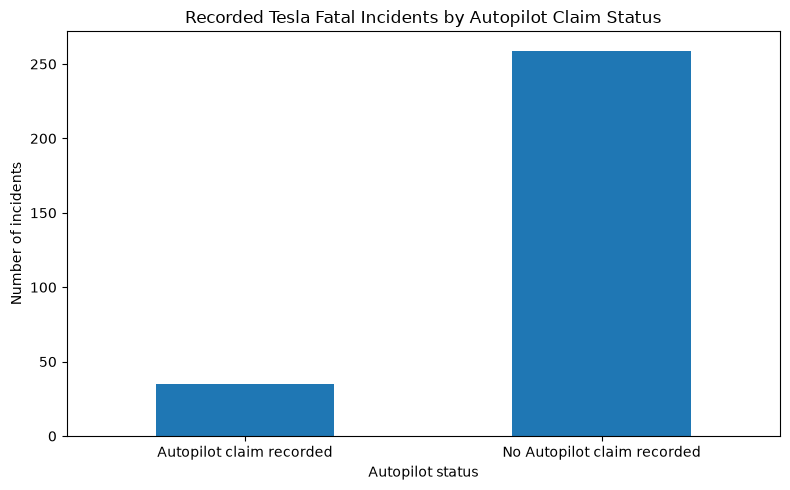


--- Verified Tesla Autopilot deaths ---
Verified Autopilot death recorded        16
No verified Autopilot death recorded    278
dtype: int64

--- Autopilot claim vs verified Autopilot death ---


Verified Autopilot death,False,True
Autopilot claim recorded,,
False,257,2
True,21,14


In [114]:
# ============================================================
# AUTOPILOT ANALYSIS — ROBUST VERSION
# ============================================================

# Start from the existing analysis dataframe
categorical_df = eda_df.copy()

print("Working dataframe:", categorical_df.shape)

# ------------------------------------------------------------
# 1. Find the actual Autopilot columns
# ------------------------------------------------------------

print("\nAutopilot-related columns found:")

autopilot_columns = [
    col for col in categorical_df.columns
    if "autopilot" in str(col).lower()
]

for col in autopilot_columns:
    print(repr(col))


# ------------------------------------------------------------
# 2. Locate the source Autopilot claimed column
# ------------------------------------------------------------

autopilot_claim_col = None

for col in categorical_df.columns:
    normalized = (
        str(col)
        .strip()
        .lower()
        .replace("_", " ")
    )

    if normalized == "autopilot claimed":
        autopilot_claim_col = col
        break

if autopilot_claim_col is None:
    raise KeyError(
        "Could not find the 'Autopilot claimed' column. "
        "Available columns are:\n"
        + "\n".join(map(str, categorical_df.columns))
    )

print("\nUsing Autopilot claim column:")
print(repr(autopilot_claim_col))


# ------------------------------------------------------------
# 3. Convert Autopilot claimed into an analysis indicator
# ------------------------------------------------------------

autopilot_claim_numeric = pd.to_numeric(
    categorical_df[autopilot_claim_col],
    errors="coerce"
)

autopilot_claimed_flag = (
    autopilot_claim_numeric.fillna(0) > 0
)


# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

autopilot_summary = pd.Series({
    "Autopilot claim recorded": int(autopilot_claimed_flag.sum()),
    "No Autopilot claim recorded": int((~autopilot_claimed_flag).sum())
})

print("\n--- Autopilot claim summary ---")
print(autopilot_summary)

print("\nTotal incidents:", len(categorical_df))
print("Autopilot claim records:", int(autopilot_claimed_flag.sum()))


# ------------------------------------------------------------
# 5. Plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

autopilot_summary.plot(kind="bar")

plt.title("Recorded Tesla Fatal Incidents by Autopilot Claim Status")
plt.xlabel("Autopilot status")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Verified Autopilot deaths
# ------------------------------------------------------------

verified_col = None

for col in categorical_df.columns:
    normalized = (
        str(col)
        .strip()
        .lower()
        .replace("_", " ")
    )

    if normalized == "verified tesla autopilot deaths count":
        verified_col = col
        break

# If the count column exists, use it
if verified_col is not None:

    verified_ap_numeric = pd.to_numeric(
        categorical_df[verified_col],
        errors="coerce"
    ).fillna(0)

else:
    # Fall back to the original field if the count column
    # doesn't exist.
    verified_original_col = None

    for col in categorical_df.columns:
        normalized = (
            str(col)
            .strip()
            .lower()
            .replace("_", " ")
        )

        if normalized == "verified tesla autopilot deaths":
            verified_original_col = col
            break

    if verified_original_col is None:
        raise KeyError(
            "Could not find either "
            "'Verified Tesla Autopilot Deaths' or its count column."
        )

    verified_ap_numeric = pd.to_numeric(
        categorical_df[verified_original_col],
        errors="coerce"
    ).fillna(0)


verified_ap_flag = verified_ap_numeric > 0


verified_ap_summary = pd.Series({
    "Verified Autopilot death recorded": int(verified_ap_flag.sum()),
    "No verified Autopilot death recorded": int((~verified_ap_flag).sum())
})

print("\n--- Verified Tesla Autopilot deaths ---")
print(verified_ap_summary)


# ------------------------------------------------------------
# 7. Cross-tabulation
# ------------------------------------------------------------

ap_comparison = pd.DataFrame({
    "Autopilot claim recorded": autopilot_claimed_flag,
    "Verified Autopilot death": verified_ap_flag
})

ap_comparison_table = pd.crosstab(
    ap_comparison["Autopilot claim recorded"],
    ap_comparison["Verified Autopilot death"]
)

print("\n--- Autopilot claim vs verified Autopilot death ---")
display(ap_comparison_table)

In [117]:
# ============================================================
# PHASE 4 — SETUP / RELOAD ANALYSIS DATA
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DATASET PATH
# ------------------------------------------------------------

ANALYSIS_READY_PATH = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_2\data\clean\tesla_deaths_analysis_ready.csv"
)

print("Dataset path:")
print(ANALYSIS_READY_PATH)

print("\nFile exists:", ANALYSIS_READY_PATH.exists())


# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

if not ANALYSIS_READY_PATH.exists():
    raise FileNotFoundError(
        f"\nDataset not found:\n{ANALYSIS_READY_PATH}\n\n"
        "Check the path above."
    )

working_df = pd.read_csv(ANALYSIS_READY_PATH)

print("\nDataset loaded successfully.")
print("Shape:", working_df.shape)


# ------------------------------------------------------------
# 3. BASIC VALIDATION
# ------------------------------------------------------------

print("\nColumns:")
print(list(working_df.columns))

print("\nUnique cases:")

if "Case #" in working_df.columns:
    print(working_df["Case #"].nunique())
else:
    print("WARNING: 'Case #' column not found.")


# ------------------------------------------------------------
# 4. DATE CONVERSION
# ------------------------------------------------------------

if "Date" in working_df.columns:

    working_df["Date"] = pd.to_datetime(
        working_df["Date"],
        errors="coerce"
    )

    print("\nDate range:")
    print(
        working_df["Date"].min(),
        "to",
        working_df["Date"].max()
    )


# ------------------------------------------------------------
# 5. CREATE ANALYSIS COPY
# ------------------------------------------------------------

analysis_df = working_df.copy()

print("\nWorking analysis dataframe:")
print("Shape:", analysis_df.shape)

if "Case #" in analysis_df.columns:
    print("Unique cases:", analysis_df["Case #"].nunique())


print("\n============================================================")
print("PHASE 4 DATASET SETUP COMPLETE")
print("============================================================")

Dataset path:
C:\Material\Repo\Projects\Capstone_1\Part_2\data\clean\tesla_deaths_analysis_ready.csv

File exists: True

Dataset loaded successfully.
Shape: (294, 41)

Columns:
['Case #', 'Year', 'Date', 'Country', 'State', 'Description', 'Deaths', 'Tesla driver', 'Tesla occupant', 'Other vehicle', 'Cyclists/ Peds', 'TSLA+cycl / peds', 'Model', 'Autopilot claimed', 'Verified Tesla Autopilot Deaths', 'Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO', 'Source_URL_1', 'Source_URL_2', 'Source', 'Note', 'Deceased 1', 'Deceased 2', 'Deceased 3', 'Deceased 4', 'Date_original', 'Year_numeric', 'Deaths_numeric', 'Date_year', 'Year_original', 'Event_year', 'Year_source_numeric', 'Year_review_flag', 'Year_anomaly_flag', 'Deaths_count', 'Tesla driver_count', 'Tesla occupant_count', 'Other vehicle_count', 'Cyclists/ Peds_count', 'TSLA+cycl / peds_count', 'Verified Tesla Autopilot Deaths_count', 'Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO_count']

Unique ca

Working dataframe shape: (294, 41)
Unique cases: 294

Date range:
2013-04-02 00:00:00 to 2023-01-17 00:00:00

--- Incidents by Country ---


,Country,Recorded_Incidents
0,USA,215
1,China,16
2,Germany,11
3,Canada,10
4,Netherlands,6
5,UK,5
6,Norway,4
7,Switzerland,3
8,Taiwan,3
9,Holland,3


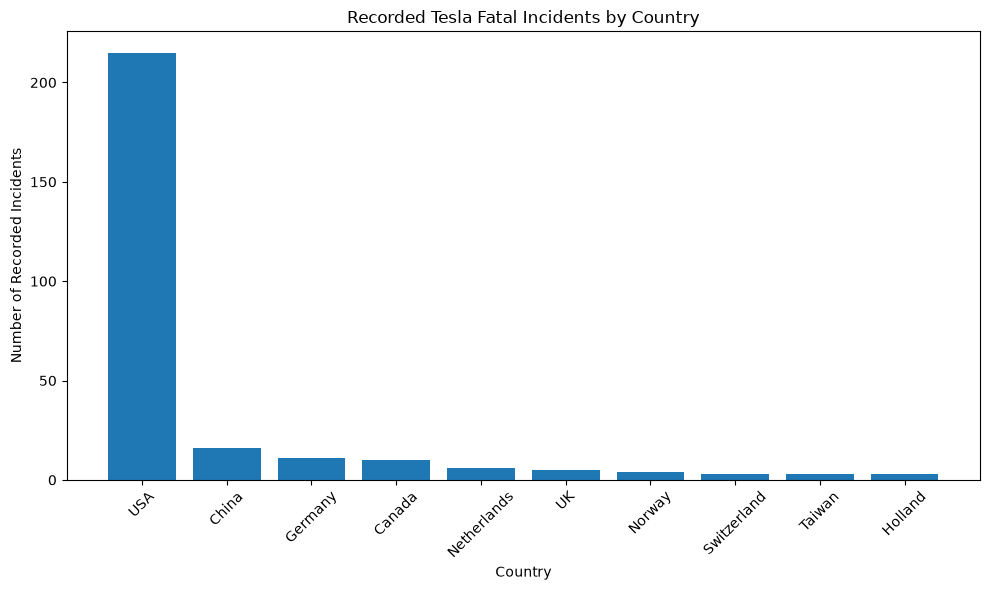


--- Recorded Incidents by U.S. State ---


,State,Recorded_Incidents
0,CA,91
1,FL,32
2,GA,9
3,AZ,8
4,PA,7
5,NY,6
6,OH,6
7,UT,5
8,MO,4
9,NV,4


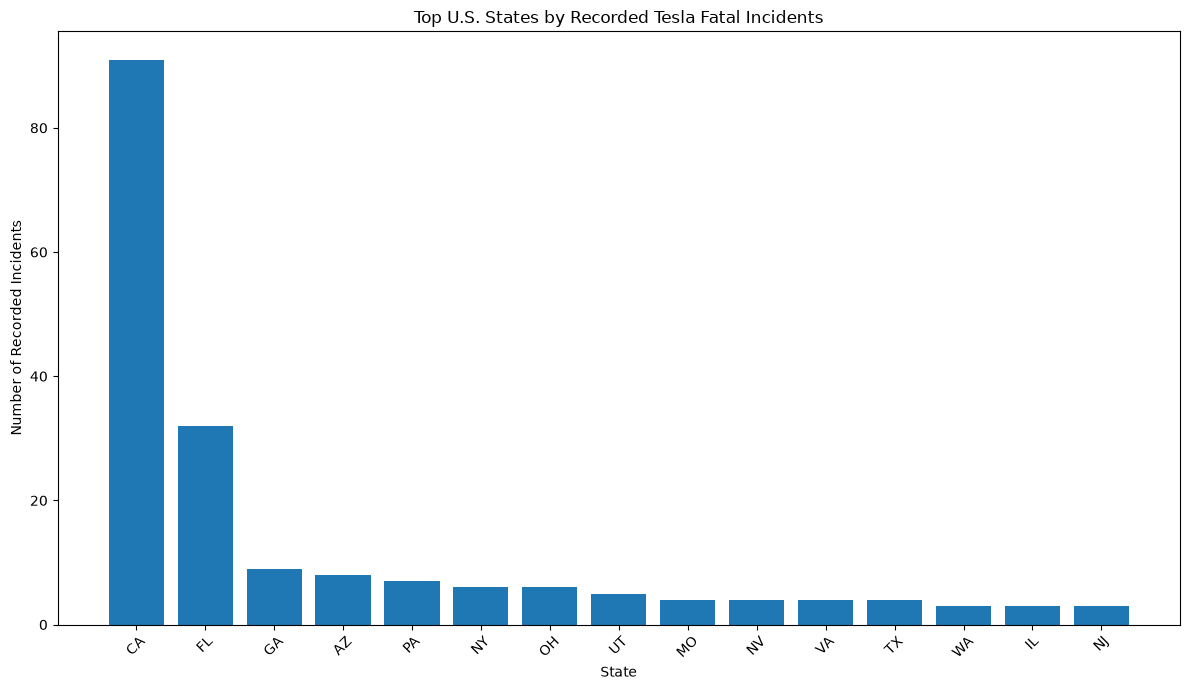


--- Tesla Driver Involvement ---


Tesla driver recorded        117
Tesla driver not recorded    177
dtype: int64

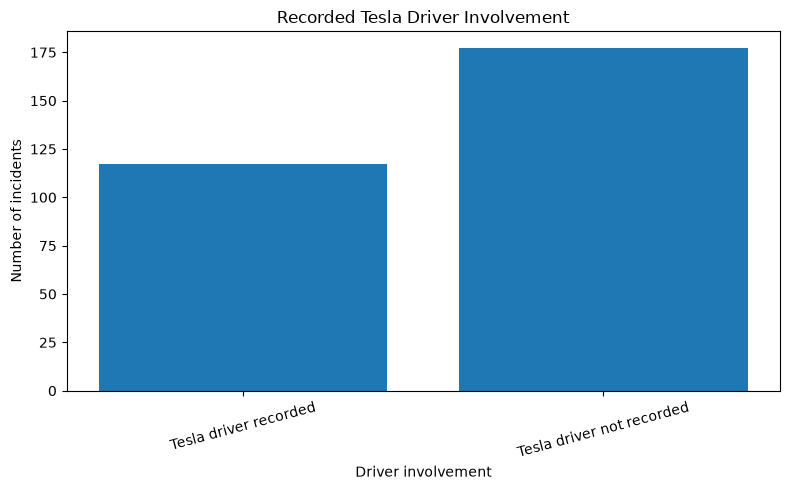


--- Tesla Occupant Involvement ---


Tesla occupant recorded         43
Tesla occupant not recorded    251
dtype: int64

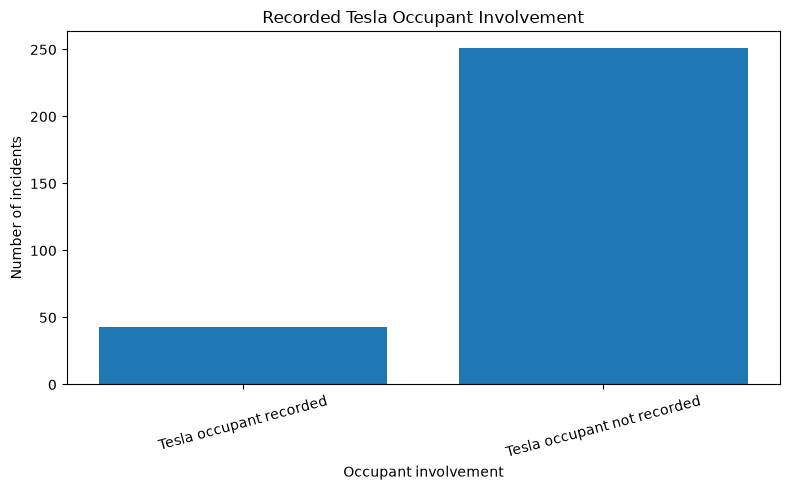


--- Other Vehicle Involvement ---


Other vehicle recorded        110
Other vehicle not recorded    184
dtype: int64

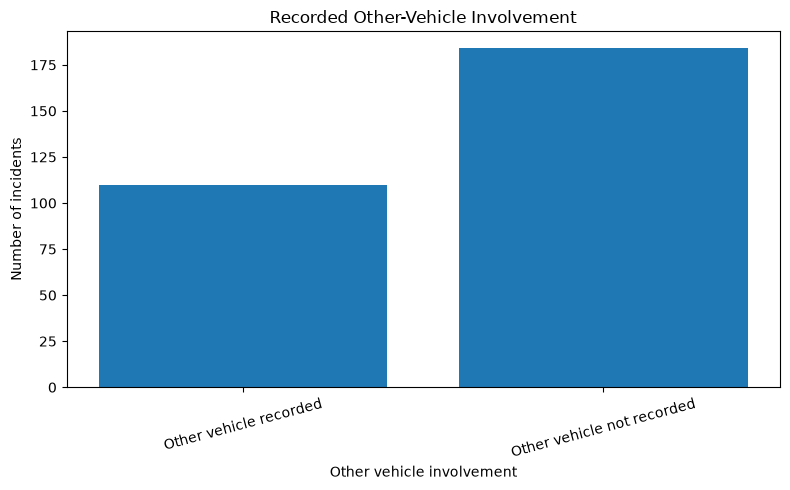


--- Cyclist/Pedestrian Involvement ---


Cyclist/Pedestrian recorded         44
Cyclist/Pedestrian not recorded    250
dtype: int64

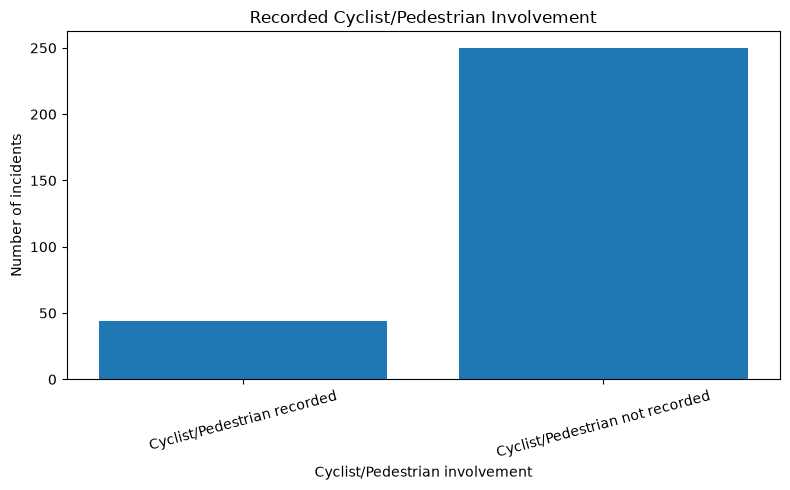


--- Autopilot Claim Status ---


Autopilot claim recorded           32
No Autopilot claim recorded         0
Autopilot claim status missing    259
dtype: int64

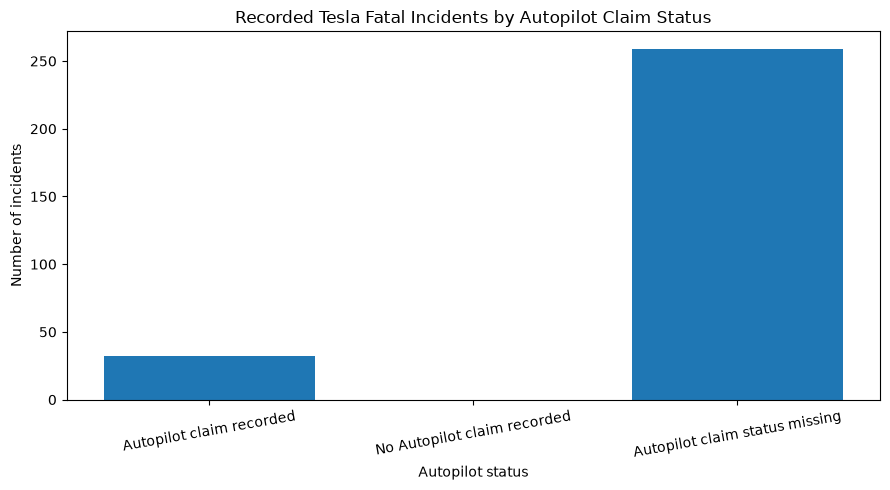


--- Verified Tesla Autopilot Deaths ---


Verified Autopilot death recorded        16
No verified Autopilot death recorded    278
dtype: int64


--- Overall Incident Characteristics ---


,Characteristic,Incidents
0,Tesla driver recorded,117
1,Tesla occupant recorded,43
2,Other vehicle recorded,110
3,Cyclist/Pedestrian recorded,44
4,Autopilot claim recorded,32
5,Verified Autopilot death recorded,16



PHASE 4 COMPLETE

Final analysis dataframe shape: (294, 41)
Unique cases: 294

Key counts:
Total incidents: 294
Autopilot claims: 32
Verified Autopilot deaths: 16


In [118]:
# ============================================================
# PHASE 4 — GEOGRAPHIC & INCIDENT CHARACTERISTICS ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VERIFY WORKING DATAFRAME
# ------------------------------------------------------------

print("Working dataframe shape:", working_df.shape)
print("Unique cases:", working_df["Case #"].nunique())

analysis_df = working_df.copy()

# Ensure date is datetime
if "Date" in analysis_df.columns:
    analysis_df["Date"] = pd.to_datetime(
        analysis_df["Date"],
        errors="coerce"
    )

print("\nDate range:")
print(analysis_df["Date"].min(), "to", analysis_df["Date"].max())


# ============================================================
# 2. COUNTRY DISTRIBUTION
# ============================================================

if "Country" in analysis_df.columns:

    country_summary = (
        analysis_df["Country"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
        .value_counts()
        .rename_axis("Country")
        .reset_index(name="Recorded_Incidents")
    )

    print("\n--- Incidents by Country ---")
    display(country_summary)

    plt.figure(figsize=(10, 6))

    top_countries = country_summary.head(10)

    plt.bar(
        top_countries["Country"],
        top_countries["Recorded_Incidents"]
    )

    plt.title("Recorded Tesla Fatal Incidents by Country")
    plt.xlabel("Country")
    plt.ylabel("Number of Recorded Incidents")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# ============================================================
# 3. TOP U.S. STATES
# ============================================================

if "State" in analysis_df.columns:

    usa_df = analysis_df[
        analysis_df["Country"]
        .fillna("")
        .astype(str)
        .str.upper()
        .str.strip()
        .eq("USA")
    ].copy()

    state_summary = (
        usa_df["State"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
        .value_counts()
        .rename_axis("State")
        .reset_index(name="Recorded_Incidents")
    )

    print("\n--- Recorded Incidents by U.S. State ---")
    display(state_summary.head(20))

    plt.figure(figsize=(12, 7))

    top_states = state_summary.head(15)

    plt.bar(
        top_states["State"],
        top_states["Recorded_Incidents"]
    )

    plt.title("Top U.S. States by Recorded Tesla Fatal Incidents")
    plt.xlabel("State")
    plt.ylabel("Number of Recorded Incidents")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# ============================================================
# 4. INCIDENT CHARACTERISTICS
# ============================================================

# Helper function:
# Count records where the corresponding field contains
# an actual recorded value.

def recorded_count(df, column):
    if column not in df.columns:
        return np.nan

    return df[column].notna().sum()


# Tesla driver
driver_recorded = recorded_count(
    analysis_df,
    "Tesla driver"
)

driver_missing = (
    len(analysis_df) - driver_recorded
)


# Tesla occupant
occupant_recorded = recorded_count(
    analysis_df,
    "Tesla occupant"
)

occupant_missing = (
    len(analysis_df) - occupant_recorded
)


# Other vehicle
other_vehicle_recorded = recorded_count(
    analysis_df,
    "Other vehicle"
)

other_vehicle_missing = (
    len(analysis_df) - other_vehicle_recorded
)


# Cyclist / pedestrian
cyclist_ped_recorded = recorded_count(
    analysis_df,
    "Cyclists/ Peds"
)

cyclist_ped_missing = (
    len(analysis_df) - cyclist_ped_recorded
)


# ============================================================
# 5. TESLA DRIVER
# ============================================================

print("\n--- Tesla Driver Involvement ---")

driver_summary = pd.Series({
    "Tesla driver recorded": driver_recorded,
    "Tesla driver not recorded": driver_missing
})

display(driver_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    driver_summary.index,
    driver_summary.values
)

plt.title("Recorded Tesla Driver Involvement")
plt.xlabel("Driver involvement")
plt.ylabel("Number of incidents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================================
# 6. TESLA OCCUPANT
# ============================================================

print("\n--- Tesla Occupant Involvement ---")

occupant_summary = pd.Series({
    "Tesla occupant recorded": occupant_recorded,
    "Tesla occupant not recorded": occupant_missing
})

display(occupant_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    occupant_summary.index,
    occupant_summary.values
)

plt.title("Recorded Tesla Occupant Involvement")
plt.xlabel("Occupant involvement")
plt.ylabel("Number of incidents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================================
# 7. OTHER VEHICLE
# ============================================================

print("\n--- Other Vehicle Involvement ---")

other_vehicle_summary = pd.Series({
    "Other vehicle recorded": other_vehicle_recorded,
    "Other vehicle not recorded": other_vehicle_missing
})

display(other_vehicle_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    other_vehicle_summary.index,
    other_vehicle_summary.values
)

plt.title("Recorded Other-Vehicle Involvement")
plt.xlabel("Other vehicle involvement")
plt.ylabel("Number of incidents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================================
# 8. CYCLIST / PEDESTRIAN
# ============================================================

print("\n--- Cyclist/Pedestrian Involvement ---")

cyclist_ped_summary = pd.Series({
    "Cyclist/Pedestrian recorded": cyclist_ped_recorded,
    "Cyclist/Pedestrian not recorded": cyclist_ped_missing
})

display(cyclist_ped_summary)

plt.figure(figsize=(8, 5))

plt.bar(
    cyclist_ped_summary.index,
    cyclist_ped_summary.values
)

plt.title("Recorded Cyclist/Pedestrian Involvement")
plt.xlabel("Cyclist/Pedestrian involvement")
plt.ylabel("Number of incidents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================================
# 9. AUTOPILOT CLAIM
# ============================================================

print("\n--- Autopilot Claim Status ---")

if "Autopilot claimed" in analysis_df.columns:

    # IMPORTANT:
    # Autopilot claimed is Boolean.
    # True = claim recorded
    # False = no claim recorded

    autopilot_claimed_count = (
        analysis_df["Autopilot claimed"]
        .eq(True)
        .sum()
    )

    no_autopilot_claim_count = (
        analysis_df["Autopilot claimed"]
        .eq(False)
        .sum()
    )

    autopilot_missing_count = (
        analysis_df["Autopilot claimed"]
        .isna()
        .sum()
    )

    autopilot_summary = pd.Series({
        "Autopilot claim recorded": autopilot_claimed_count,
        "No Autopilot claim recorded": no_autopilot_claim_count,
        "Autopilot claim status missing": autopilot_missing_count
    })

    display(autopilot_summary)

    plt.figure(figsize=(9, 5))

    plt.bar(
        autopilot_summary.index,
        autopilot_summary.values
    )

    plt.title("Recorded Tesla Fatal Incidents by Autopilot Claim Status")
    plt.xlabel("Autopilot status")
    plt.ylabel("Number of incidents")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()


# ============================================================
# 10. VERIFIED AUTOPILOT DEATH
# ============================================================

print("\n--- Verified Tesla Autopilot Deaths ---")

if "Verified Tesla Autopilot Deaths" in analysis_df.columns:

    verified_autopilot_count = (
        analysis_df["Verified Tesla Autopilot Deaths"]
        .notna()
        .sum()
    )

    no_verified_autopilot_count = (
        len(analysis_df) - verified_autopilot_count
    )

    verified_summary = pd.Series({
        "Verified Autopilot death recorded":
            verified_autopilot_count,

        "No verified Autopilot death recorded":
            no_verified_autopilot_count
    })

    display(verified_summary)


# ============================================================
# 11. OVERALL INCIDENT CHARACTERISTICS
# ============================================================

characteristic_summary = pd.DataFrame({
    "Characteristic": [
        "Tesla driver recorded",
        "Tesla occupant recorded",
        "Other vehicle recorded",
        "Cyclist/Pedestrian recorded",
        "Autopilot claim recorded",
        "Verified Autopilot death recorded"
    ],

    "Incidents": [
        driver_recorded,
        occupant_recorded,
        other_vehicle_recorded,
        cyclist_ped_recorded,
        autopilot_claimed_count
            if "Autopilot claimed" in analysis_df.columns
            else np.nan,
        verified_autopilot_count
            if "Verified Tesla Autopilot Deaths"
            in analysis_df.columns
            else np.nan
    ]
})

print("\n--- Overall Incident Characteristics ---")
display(characteristic_summary)


# ============================================================
# 12. FINAL VALIDATION
# ============================================================

print("\n============================================================")
print("PHASE 4 COMPLETE")
print("============================================================")

print("\nFinal analysis dataframe shape:", analysis_df.shape)
print("Unique cases:", analysis_df["Case #"].nunique())

print("\nKey counts:")
print("Total incidents:", len(analysis_df))
print("Autopilot claims:", autopilot_claimed_count)
print("Verified Autopilot deaths:", verified_autopilot_count)

In [119]:
# ============================================================
# PHASE 5 — TESLA MODEL & FATALITY CHARACTERISTICS ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VERIFY CURRENT DATAFRAME
# ------------------------------------------------------------

# Use the dataframe that exists in the current notebook.
# If analysis_df already exists from Phase 4, use it.
if "analysis_df" in globals():
    phase5_df = analysis_df.copy()

elif "working_df" in globals():
    phase5_df = working_df.copy()

else:
    raise NameError(
        "Neither 'analysis_df' nor 'working_df' exists. "
        "Reload the analysis-ready dataset before continuing."
    )

print("Phase 5 dataframe shape:", phase5_df.shape)

if "Case #" in phase5_df.columns:
    print("Unique cases:", phase5_df["Case #"].nunique())

print("\nAvailable columns:")
for i, col in enumerate(phase5_df.columns, start=1):
    print(f"{i:02d}. {col}")


# ============================================================
# 2. HELPER FUNCTION FOR COLUMN DETECTION
# ============================================================

def find_column(possible_names):
    """
    Return the first matching column from possible_names.
    Matching is case-insensitive and ignores leading/trailing spaces.
    """
    
    normalized = {
        str(col).strip().lower(): col
        for col in phase5_df.columns
    }

    for name in possible_names:
        key = str(name).strip().lower()

        if key in normalized:
            return normalized[key]

    return None


# ============================================================
# 3. IDENTIFY IMPORTANT COLUMNS
# ============================================================

model_col = find_column([
    "Model",
    "Tesla Model",
    "Tesla model"
])

deaths_col = find_column([
    "Deaths",
    "Deaths_count"
])

driver_col = find_column([
    "Tesla driver",
    "Tesla driver_count"
])

occupant_col = find_column([
    "Tesla occupant",
    "Tesla occupant_count"
])

other_vehicle_col = find_column([
    "Other vehicle",
    "Other vehicle_count"
])

cyclist_ped_col = find_column([
    "Cyclists/ Peds",
    "Cyclists/ Peds_count"
])

autopilot_col = find_column([
    "Verified Tesla Autopilot Deaths_count",
    "Verified Tesla Autopilot Deaths"
])

date_col = find_column([
    "Date",
    "Event Date"
])

year_col = find_column([
    "Event_year",
    "Event year",
    "Year"
])


print("\n--- Detected columns ---")
print("Model:", model_col)
print("Deaths:", deaths_col)
print("Tesla driver:", driver_col)
print("Tesla occupant:", occupant_col)
print("Other vehicle:", other_vehicle_col)
print("Cyclist/Pedestrian:", cyclist_ped_col)
print("Verified Autopilot deaths:", autopilot_col)
print("Date:", date_col)
print("Year:", year_col)

Phase 5 dataframe shape: (294, 41)
Unique cases: 294

Available columns:
01. Case #
02. Year
03. Date
04. Country
05. State
06. Description
07. Deaths
08. Tesla driver
09. Tesla occupant
10. Other vehicle
11. Cyclists/ Peds
12. TSLA+cycl / peds
13. Model
14. Autopilot claimed
15. Verified Tesla Autopilot Deaths
16. Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO
17. Source_URL_1
18. Source_URL_2
19. Source
20. Note
21. Deceased 1
22. Deceased 2
23. Deceased 3
24. Deceased 4
25. Date_original
26. Year_numeric
27. Deaths_numeric
28. Date_year
29. Year_original
30. Event_year
31. Year_source_numeric
32. Year_review_flag
33. Year_anomaly_flag
34. Deaths_count
35. Tesla driver_count
36. Tesla occupant_count
37. Other vehicle_count
38. Cyclists/ Peds_count
39. TSLA+cycl / peds_count
40. Verified Tesla Autopilot Deaths_count
41. Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO_count

--- Detected columns ---
Model: Model
Deaths: Deaths
Tesla driver: Tesla 


--- Tesla Model Distribution ---


,Tesla_Model,Recorded_Incidents
0,Unknown,181
1,S,45
2,3,39
3,X,17
4,Y,10
5,1,1
6,2,1


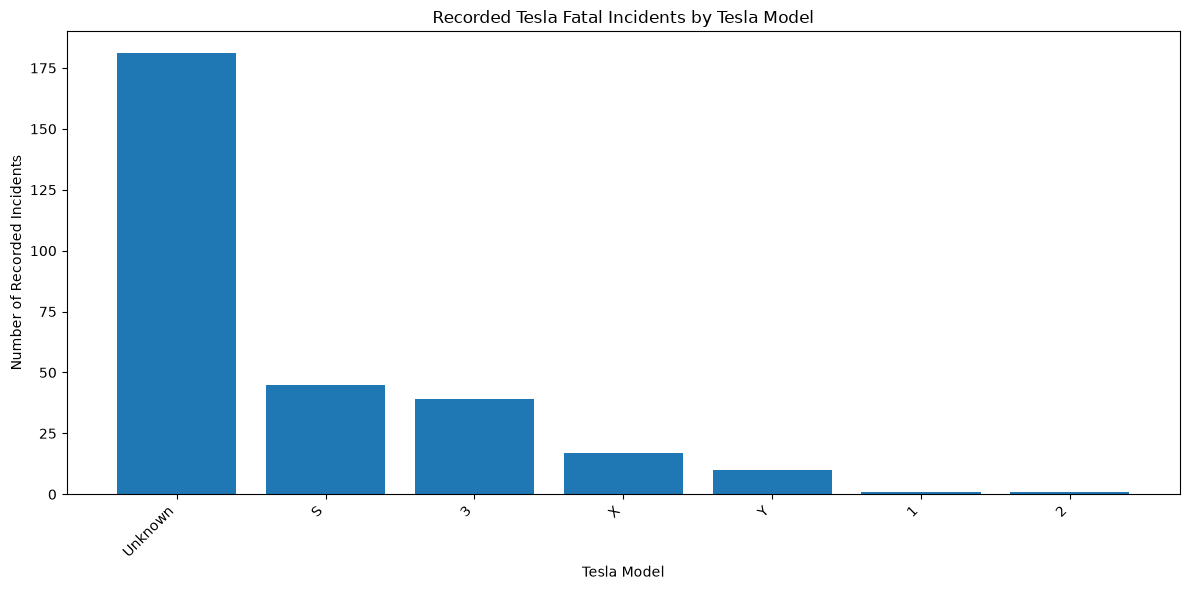

In [120]:
# ============================================================
# 4. TESLA MODEL DISTRIBUTION
# ============================================================

if model_col is None:

    print("Tesla model column was not found.")

else:

    model_data = (
        phase5_df[model_col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    model_summary = (
        model_data
        .value_counts()
        .rename_axis("Tesla_Model")
        .reset_index(name="Recorded_Incidents")
    )

    print("\n--- Tesla Model Distribution ---")
    display(model_summary)

    plt.figure(figsize=(12, 6))

    top_models = model_summary.head(15)

    plt.bar(
        top_models["Tesla_Model"],
        top_models["Recorded_Incidents"]
    )

    plt.title("Recorded Tesla Fatal Incidents by Tesla Model")
    plt.xlabel("Tesla Model")
    plt.ylabel("Number of Recorded Incidents")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()


--- Recorded Deaths by Tesla Model ---


,_Model,Recorded_Incidents,Recorded_Deaths
4,Unknown,181,219.0
3,S,45,53.0
2,3,39,47.0
5,X,17,19.0
6,Y,10,13.0
1,2,1,1.0
0,1,1,1.0


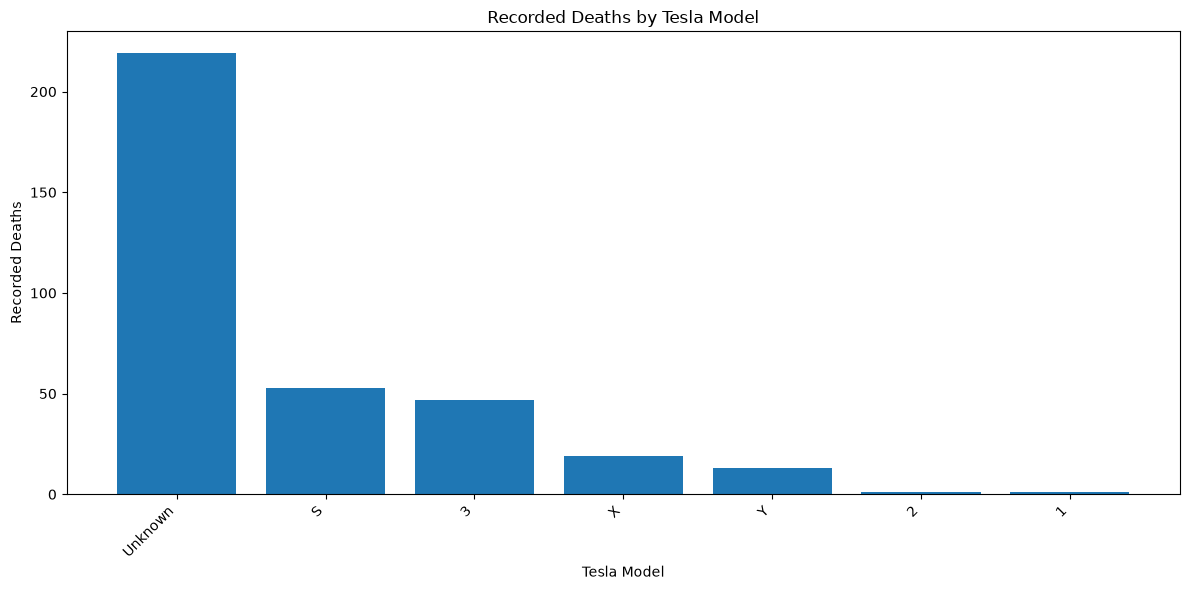

In [121]:
# ============================================================
# 5. RECORDED DEATHS BY TESLA MODEL
# ============================================================

if model_col is None or deaths_col is None:

    print("Model or Deaths column not available.")

else:

    model_deaths_df = phase5_df.copy()

    model_deaths_df["_Model"] = (
        model_deaths_df[model_col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    model_deaths_df["_Deaths"] = pd.to_numeric(
        model_deaths_df[deaths_col],
        errors="coerce"
    ).fillna(0)

    model_deaths_summary = (
        model_deaths_df
        .groupby("_Model", as_index=False)
        .agg(
            Recorded_Incidents=("_Model", "size"),
            Recorded_Deaths=("_Deaths", "sum")
        )
        .sort_values(
            "Recorded_Deaths",
            ascending=False
        )
    )

    print("\n--- Recorded Deaths by Tesla Model ---")
    display(model_deaths_summary)

    plt.figure(figsize=(12, 6))

    top_models_deaths = model_deaths_summary.head(15)

    plt.bar(
        top_models_deaths["_Model"],
        top_models_deaths["Recorded_Deaths"]
    )

    plt.title("Recorded Deaths by Tesla Model")
    plt.xlabel("Tesla Model")
    plt.ylabel("Recorded Deaths")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()


--- Death Severity by Tesla Model ---


,_Model,Recorded_Incidents,Total_Deaths,Mean_Deaths_Per_Incident
4,Unknown,181,219.0,1.209945
3,S,45,53.0,1.177778
2,3,39,47.0,1.205128
5,X,17,19.0,1.117647
6,Y,10,13.0,1.300000
1,2,1,1.0,1.000000
0,1,1,1.0,1.000000


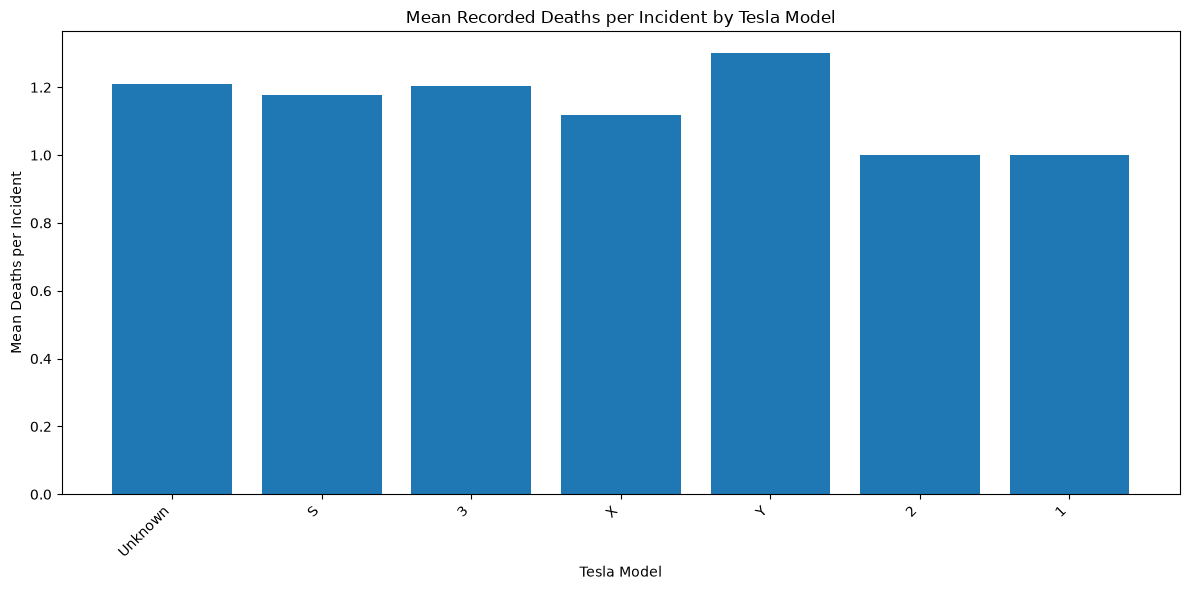

In [122]:
# ============================================================
# 6. AVERAGE DEATHS PER INCIDENT BY MODEL
# ============================================================

if model_col is not None and deaths_col is not None:

    model_severity = phase5_df.copy()

    model_severity["_Model"] = (
        model_severity[model_col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    model_severity["_Deaths"] = pd.to_numeric(
        model_severity[deaths_col],
        errors="coerce"
    )

    model_severity_summary = (
        model_severity
        .groupby("_Model", as_index=False)
        .agg(
            Recorded_Incidents=("_Model", "size"),
            Total_Deaths=("_Deaths", "sum"),
            Mean_Deaths_Per_Incident=("_Deaths", "mean")
        )
        .sort_values(
            "Total_Deaths",
            ascending=False
        )
    )

    print("\n--- Death Severity by Tesla Model ---")
    display(model_severity_summary)

    plt.figure(figsize=(12, 6))

    plot_df = model_severity_summary.head(15)

    plt.bar(
        plot_df["_Model"],
        plot_df["Mean_Deaths_Per_Incident"]
    )

    plt.title("Mean Recorded Deaths per Incident by Tesla Model")
    plt.xlabel("Tesla Model")
    plt.ylabel("Mean Deaths per Incident")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

In [123]:
# ============================================================
# 7. TESLA DRIVER DEATH INVOLVEMENT
# ============================================================

if driver_col is not None:

    driver_data = pd.to_numeric(
        phase5_df[driver_col],
        errors="coerce"
    )

    driver_summary = pd.Series({
        "Incidents with Tesla driver death recorded":
            driver_data.fillna(0).gt(0).sum(),

        "Total Tesla driver deaths recorded":
            driver_data.fillna(0).sum()
    })

    print("\n--- Tesla Driver Deaths ---")
    display(driver_summary)


--- Tesla Driver Deaths ---


Incidents with Tesla driver death recorded    117.0
Total Tesla driver deaths recorded            117.0
dtype: float64

In [124]:
# ============================================================
# 8. TESLA OCCUPANT DEATH INVOLVEMENT
# ============================================================

if occupant_col is not None:

    occupant_data = pd.to_numeric(
        phase5_df[occupant_col],
        errors="coerce"
    )

    occupant_summary = pd.Series({
        "Incidents with Tesla occupant deaths recorded":
            occupant_data.fillna(0).gt(0).sum(),

        "Total Tesla occupant deaths recorded":
            occupant_data.fillna(0).sum()
    })

    print("\n--- Tesla Occupant Deaths ---")
    display(occupant_summary)


--- Tesla Occupant Deaths ---


Incidents with Tesla occupant deaths recorded    43.0
Total Tesla occupant deaths recorded             48.0
dtype: float64

In [125]:
# ============================================================
# 9. CYCLIST / PEDESTRIAN DEATH INVOLVEMENT
# ============================================================

if cyclist_ped_col is not None:

    cyclist_ped_data = pd.to_numeric(
        phase5_df[cyclist_ped_col],
        errors="coerce"
    )

    cyclist_ped_summary = pd.Series({
        "Incidents with cyclist/pedestrian deaths recorded":
            cyclist_ped_data.fillna(0).gt(0).sum(),

        "Total cyclist/pedestrian deaths recorded":
            cyclist_ped_data.fillna(0).sum()
    })

    print("\n--- Cyclist/Pedestrian Deaths ---")
    display(cyclist_ped_summary)


--- Cyclist/Pedestrian Deaths ---


Incidents with cyclist/pedestrian deaths recorded    44.0
Total cyclist/pedestrian deaths recorded             46.0
dtype: float64

In [126]:
# ============================================================
# 10. OTHER VEHICLE DEATH INVOLVEMENT
# ============================================================

if other_vehicle_col is not None:

    other_vehicle_data = pd.to_numeric(
        phase5_df[other_vehicle_col],
        errors="coerce"
    )

    other_vehicle_summary = pd.Series({
        "Incidents with other-vehicle deaths recorded":
            other_vehicle_data.fillna(0).gt(0).sum(),

        "Total other-vehicle deaths recorded":
            other_vehicle_data.fillna(0).sum()
    })

    print("\n--- Other Vehicle Deaths ---")
    display(other_vehicle_summary)


--- Other Vehicle Deaths ---


Incidents with other-vehicle deaths recorded    110.0
Total other-vehicle deaths recorded             130.0
dtype: float64


--- Verified Tesla Autopilot Deaths by Year ---


,_Year,Verified_Autopilot_Deaths
0,2013,0.0
1,2014,0.0
2,2015,0.0
3,2016,2.0
4,2017,0.0
5,2018,2.0
6,2019,6.0
7,2020,1.0
8,2021,1.0
9,2022,7.0


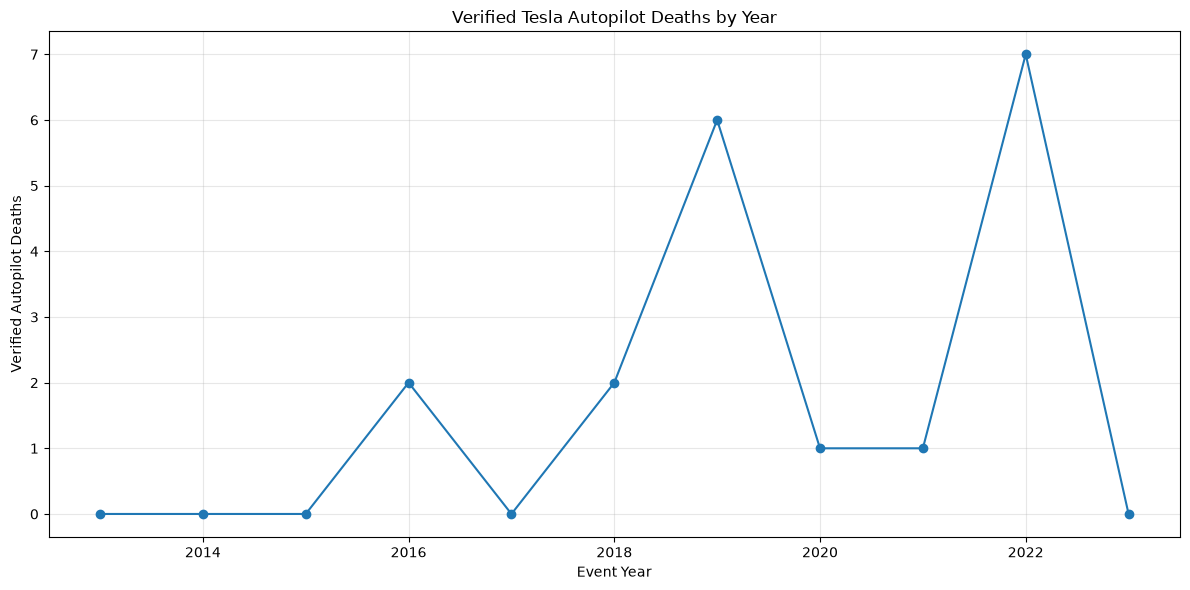

In [127]:
# ============================================================
# 11. VERIFIED TESLA AUTOPILOT DEATHS BY YEAR
# ============================================================

if autopilot_col is not None and year_col is not None:

    autopilot_year_df = phase5_df.copy()

    autopilot_year_df["_Year"] = pd.to_numeric(
        autopilot_year_df[year_col],
        errors="coerce"
    )

    autopilot_year_df["_Verified_Autopilot_Deaths"] = pd.to_numeric(
        autopilot_year_df[autopilot_col],
        errors="coerce"
    ).fillna(0)

    autopilot_year_summary = (
        autopilot_year_df
        .groupby("_Year", as_index=False)
        .agg(
            Verified_Autopilot_Deaths=(
                "_Verified_Autopilot_Deaths",
                "sum"
            )
        )
        .sort_values("_Year")
    )

    print("\n--- Verified Tesla Autopilot Deaths by Year ---")
    display(autopilot_year_summary)

    plt.figure(figsize=(12, 6))

    plt.plot(
        autopilot_year_summary["_Year"],
        autopilot_year_summary["Verified_Autopilot_Deaths"],
        marker="o"
    )

    plt.title("Verified Tesla Autopilot Deaths by Year")
    plt.xlabel("Event Year")
    plt.ylabel("Verified Autopilot Deaths")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [128]:
# ============================================================
# 12. PHASE 5 SUMMARY
# ============================================================

print("\n============================================================")
print("PHASE 5 COMPLETE")
print("============================================================")

print("Final dataframe shape:", phase5_df.shape)

if "Case #" in phase5_df.columns:
    print("Unique cases:", phase5_df["Case #"].nunique())

if deaths_col is not None:
    total_deaths = pd.to_numeric(
        phase5_df[deaths_col],
        errors="coerce"
    ).sum()

    print("Total recorded deaths:", total_deaths)

if driver_col is not None:
    driver_deaths = pd.to_numeric(
        phase5_df[driver_col],
        errors="coerce"
    ).fillna(0).sum()

    print("Tesla driver deaths:", driver_deaths)

if occupant_col is not None:
    occupant_deaths = pd.to_numeric(
        phase5_df[occupant_col],
        errors="coerce"
    ).fillna(0).sum()

    print("Tesla occupant deaths:", occupant_deaths)

if cyclist_ped_col is not None:
    cyclist_ped_deaths = pd.to_numeric(
        phase5_df[cyclist_ped_col],
        errors="coerce"
    ).fillna(0).sum()

    print("Cyclist/Pedestrian deaths:", cyclist_ped_deaths)

if autopilot_col is not None:
    verified_ap_deaths = pd.to_numeric(
        phase5_df[autopilot_col],
        errors="coerce"
    ).fillna(0).sum()

    print("Verified Autopilot deaths:", verified_ap_deaths)

print("============================================================")


PHASE 5 COMPLETE
Final dataframe shape: (294, 41)
Unique cases: 294
Total recorded deaths: 353.0
Tesla driver deaths: 117.0
Tesla occupant deaths: 48.0
Cyclist/Pedestrian deaths: 46.0
Verified Autopilot deaths: 19.0


PHASE 6 — RELATIONSHIP & ASSOCIATION ANALYSIS

Working dataframe shape: (294, 41)
Unique cases: 294

--- Identified columns ---
Year: Event_year
Tesla Model: Model
Autopilot claim: Autopilot claimed
Verified Autopilot deaths: Verified Tesla Autopilot Deaths_count
Total deaths: Deaths
Tesla driver: Tesla driver
Tesla occupant: Tesla occupant
Other vehicle: Other vehicle
Cyclist/Pedestrian: Cyclists/ Peds
Country: Country
State: State


5. AUTOPILOT CLAIM VS VERIFIED AUTOPILOT DEATH

--- Autopilot claim vs verified death ---


,No verified Autopilot death,Verified Autopilot death
No claim recorded,257,2
Claim recorded,21,14



Chi-square statistic: 84.7362
Chi-square p-value: 0.0

Expected frequencies:


_verified_autopilot_death,False,True
_autopilot_claim,,
False,244.904762,14.095238
True,33.095238,1.904762



Fisher's exact odds ratio: 85.6667
Fisher's exact p-value: 0.0


6. YEAR VS VERIFIED AUTOPILOT DEATHS

--- Verified Autopilot deaths by year ---


,Event_Year,Verified_Autopilot_Deaths
0,2013,0.0
1,2014,0.0
2,2015,0.0
3,2016,2.0
4,2017,0.0
5,2018,2.0
6,2019,6.0
7,2020,1.0
8,2021,1.0
9,2022,7.0



Spearman correlation between year and verified Autopilot deaths:
rho = 0.436
p-value = 0.180057


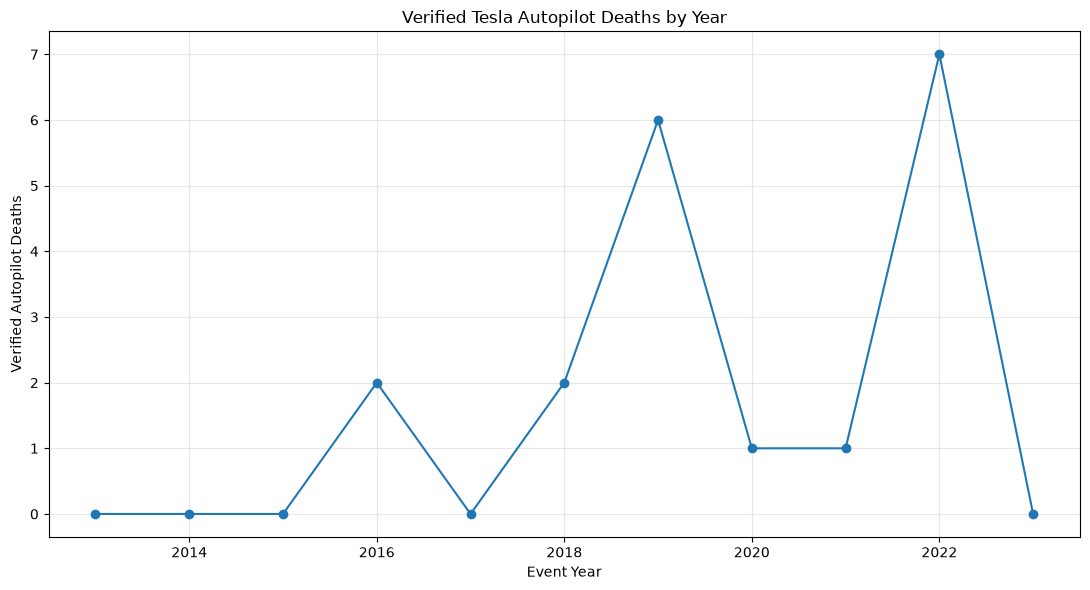



7. TESLA MODEL VS RECORDED DEATHS

--- Model-level fatality summary ---


,Tesla_Model,Recorded_Incidents,Recorded_Deaths,Mean_Deaths_Per_Incident
0,Unknown,181,219.0,1.209945
1,S,45,53.0,1.177778
2,3,39,47.0,1.205128
3,X,17,19.0,1.117647
4,Y,10,13.0,1.300000
5,2,1,1.0,1.000000
6,1,1,1.0,1.000000




8. INCIDENT CHARACTERISTIC ASSOCIATIONS

Binary characteristic columns:
['_driver_recorded', '_occupant_recorded', '_other_vehicle_recorded', '_cyclist_ped_recorded', '_autopilot_claim_recorded', '_verified_autopilot_death']

--- Incident characteristic association matrix ---


,Tesla driver,Tesla occupant,Other vehicle,Cyclist/Pedestrian,Autopilot claim,Verified Autopilot death
Tesla driver,1.000,0.076,-0.557,-0.341,-0.041,-0.042
Tesla occupant,0.076,1.000,-0.300,-0.147,0.026,-0.014
Other vehicle,-0.557,-0.300,1.000,-0.305,-0.024,0.062
Cyclist/Pedestrian,-0.341,-0.147,-0.305,1.000,0.022,-0.017
Autopilot claim,-0.041,0.026,-0.024,0.022,1.000,0.560
Verified Autopilot death,-0.042,-0.014,0.062,-0.017,0.560,1.000


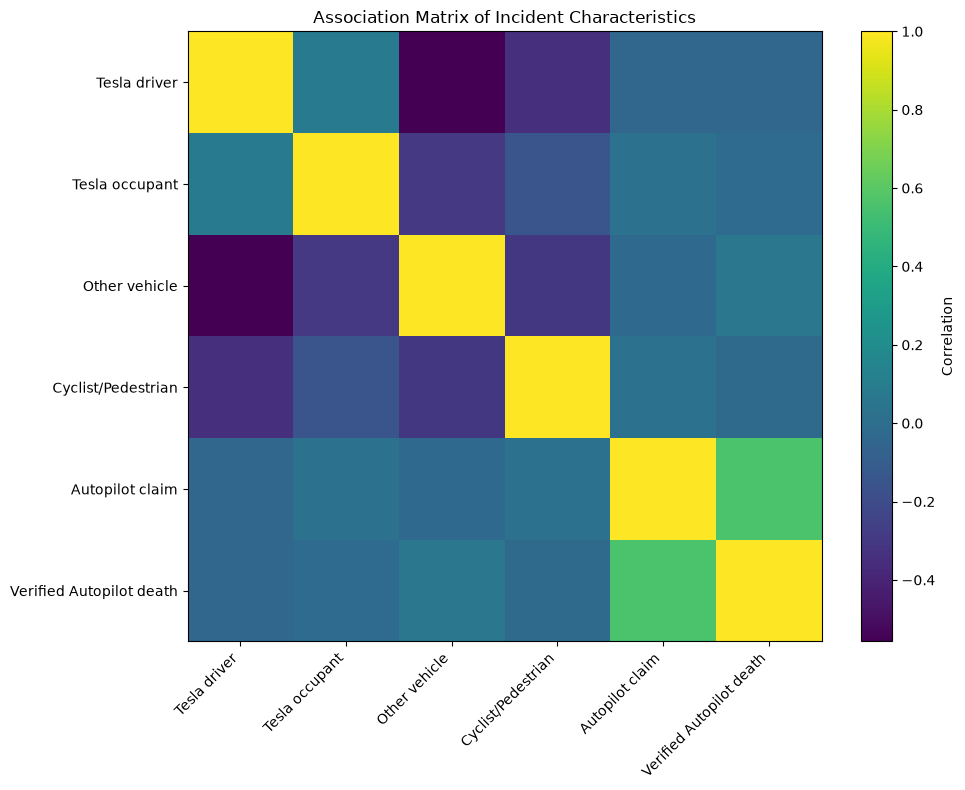


--- Country-level incident characteristics ---


,Country,Recorded_Incidents,Driver_Recorded,Occupant_Recorded,Other_Vehicle_Recorded,Cyclist_Pedestrian_Recorded,Autopilot_Claims,Verified_Autopilot_Deaths
0,USA,215,89,37,86,26,27,13
1,China,16,5,1,3,8,2,1
2,Germany,11,4,0,4,2,2,0
3,Canada,10,6,2,1,2,0,0
4,Netherlands,6,3,0,1,0,0,0
5,UK,5,1,0,3,1,0,0
6,Norway,4,1,0,2,0,1,1
7,Taiwan,3,2,0,0,1,0,0
8,Switzerland,3,1,0,2,0,0,0
9,Holland,3,1,1,1,0,1,0




12. DEATHS VS INCIDENT CHARACTERISTICS

--- Association between incident characteristics and recorded deaths ---


,Characteristic,Spearman_rho,p_value
0,_occupant_recorded,0.4214,0.0000
1,_driver_recorded,0.1171,0.0448
2,_other_vehicle_recorded,0.0500,0.3931
3,_autopilot_claim_recorded,0.0149,0.7995
4,_verified_autopilot_death,0.0143,0.8071
5,_cyclist_ped_recorded,-0.0819,0.1612




PHASE 6 COMPLETE
Final dataframe shape: (294, 49)
Unique cases: 294

Total recorded deaths: 353.0
Verified Autopilot death records: 16
Autopilot claim records: 35



In [129]:
# ============================================================
# PHASE 6 — RELATIONSHIP & ASSOCIATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, fisher_exact, spearmanr

print("============================================================")
print("PHASE 6 — RELATIONSHIP & ASSOCIATION ANALYSIS")
print("============================================================")

# ------------------------------------------------------------
# 1. VERIFY DATAFRAME
# ------------------------------------------------------------

# If working_df exists, use it.
# Otherwise fall back to analysis_df from Phase 4/5.

if "working_df" in globals():
    phase6_df = working_df.copy()
elif "analysis_df" in globals():
    phase6_df = analysis_df.copy()
else:
    raise NameError(
        "Neither working_df nor analysis_df exists. "
        "Please rerun the dataframe preparation cell from Phase 4."
    )

print("\nWorking dataframe shape:", phase6_df.shape)

if "Case #" in phase6_df.columns:
    print("Unique cases:", phase6_df["Case #"].nunique())


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def find_column(possible_names, dataframe):
    """
    Return the first matching column from a list of possible names.
    """
    for col in possible_names:
        if col in dataframe.columns:
            return col
    return None


def numeric_series(dataframe, column):
    """
    Convert a column to numeric safely.
    """
    return pd.to_numeric(
        dataframe[column],
        errors="coerce"
    )


# ============================================================
# 3. IDENTIFY IMPORTANT COLUMNS
# ============================================================

year_col = find_column(
    ["Event_year", "Year"],
    phase6_df
)

model_col = find_column(
    ["Tesla Model", "Tesla model", "Model"],
    phase6_df
)

autopilot_claim_col = find_column(
    [
        "Autopilot claimed",
        "Autopilot_claimed"
    ],
    phase6_df
)

verified_autopilot_count_col = find_column(
    [
        "Verified Tesla Autopilot Deaths_count",
        "Verified Autopilot Deaths_count"
    ],
    phase6_df
)

total_deaths_col = find_column(
    [
        "Deaths",
        "Recorded Deaths",
        "Total Deaths",
        "Deaths_count"
    ],
    phase6_df
)

driver_col = find_column(
    [
        "Tesla driver",
        "Tesla Driver"
    ],
    phase6_df
)

occupant_col = find_column(
    [
        "Tesla occupant",
        "Tesla Occupant"
    ],
    phase6_df
)

other_vehicle_col = find_column(
    [
        "Other vehicle",
        "Other Vehicle"
    ],
    phase6_df
)

cyclist_ped_col = find_column(
    [
        "Cyclists/ Peds",
        "Cyclists/Peds",
        "Cyclist/Pedestrian"
    ],
    phase6_df
)

country_col = find_column(
    ["Country"],
    phase6_df
)

state_col = find_column(
    ["State"],
    phase6_df
)


print("\n--- Identified columns ---")

print("Year:", year_col)
print("Tesla Model:", model_col)
print("Autopilot claim:", autopilot_claim_col)
print("Verified Autopilot deaths:", verified_autopilot_count_col)
print("Total deaths:", total_deaths_col)
print("Tesla driver:", driver_col)
print("Tesla occupant:", occupant_col)
print("Other vehicle:", other_vehicle_col)
print("Cyclist/Pedestrian:", cyclist_ped_col)
print("Country:", country_col)
print("State:", state_col)


# ============================================================
# 4. CREATE ANALYSIS FLAGS
# ============================================================

# ------------------------------------------------------------
# Verified Autopilot death flag
# ------------------------------------------------------------

if verified_autopilot_count_col is not None:

    phase6_df["_verified_autopilot_death"] = (
        numeric_series(
            phase6_df,
            verified_autopilot_count_col
        )
        .fillna(0)
        .gt(0)
    )

else:
    phase6_df["_verified_autopilot_death"] = False


# ------------------------------------------------------------
# Total death count
# ------------------------------------------------------------

if total_deaths_col is not None:

    phase6_df["_total_deaths"] = (
        numeric_series(
            phase6_df,
            total_deaths_col
        )
        .fillna(0)
    )

else:

    # Try to use already-created death count columns
    possible_death_count = find_column(
        [
            "Recorded_Deaths",
            "Deaths_count"
        ],
        phase6_df
    )

    if possible_death_count is not None:
        phase6_df["_total_deaths"] = (
            numeric_series(
                phase6_df,
                possible_death_count
            )
            .fillna(0)
        )
    else:
        phase6_df["_total_deaths"] = np.nan


# ============================================================
# 5. AUTOPILOT CLAIM → VERIFIED AUTOPILOT DEATH
# ============================================================

print("\n")
print("============================================================")
print("5. AUTOPILOT CLAIM VS VERIFIED AUTOPILOT DEATH")
print("============================================================")

if (
    autopilot_claim_col is not None
    and verified_autopilot_count_col is not None
):

    # Use the existing claim field.
    claim_text = (
        phase6_df[autopilot_claim_col]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Treat an actual recorded claim as True.
    # Missing values remain False for this association analysis.
    phase6_df["_autopilot_claim"] = (
        claim_text.ne("")
        & ~claim_text.isin(
            ["nan", "none", "no", "false", "0"]
        )
    )

    autopilot_crosstab = pd.crosstab(
        phase6_df["_autopilot_claim"],
        phase6_df["_verified_autopilot_death"]
    )

    autopilot_crosstab.index = [
        "No claim recorded" if x is False
        else "Claim recorded"
        for x in autopilot_crosstab.index
    ]

    autopilot_crosstab.columns = [
        "No verified Autopilot death",
        "Verified Autopilot death"
    ]

    print("\n--- Autopilot claim vs verified death ---")
    display(autopilot_crosstab)


    # --------------------------------------------------------
    # Chi-square / Fisher exact test
    # --------------------------------------------------------

    contingency = pd.crosstab(
        phase6_df["_autopilot_claim"],
        phase6_df["_verified_autopilot_death"]
    )

    # Make sure the table is 2x2
    contingency = contingency.reindex(
        index=[False, True],
        columns=[False, True],
        fill_value=0
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    print("\nChi-square statistic:", round(chi2, 4))
    print("Chi-square p-value:", round(p_value, 6))

    print("\nExpected frequencies:")
    display(
        pd.DataFrame(
            expected,
            index=contingency.index,
            columns=contingency.columns
        )
    )

    # Fisher's exact test is especially useful if expected
    # cell counts are small.
    odds_ratio, fisher_p = fisher_exact(
        contingency
    )

    print("\nFisher's exact odds ratio:", round(odds_ratio, 4))
    print("Fisher's exact p-value:", round(fisher_p, 6))

else:

    print(
        "Required Autopilot columns were not available."
    )


# ============================================================
# 6. YEAR VS VERIFIED AUTOPILOT DEATHS
# ============================================================

print("\n")
print("============================================================")
print("6. YEAR VS VERIFIED AUTOPILOT DEATHS")
print("============================================================")

if (
    year_col is not None
    and verified_autopilot_count_col is not None
):

    year_autopilot = (
        phase6_df
        .assign(
            _year_numeric=pd.to_numeric(
                phase6_df[year_col],
                errors="coerce"
            ),
            _autopilot_deaths=numeric_series(
                phase6_df,
                verified_autopilot_count_col
            ).fillna(0)
        )
        .dropna(subset=["_year_numeric"])
        .groupby("_year_numeric")["_autopilot_deaths"]
        .sum()
        .reset_index()
    )

    year_autopilot.columns = [
        "Event_Year",
        "Verified_Autopilot_Deaths"
    ]

    print("\n--- Verified Autopilot deaths by year ---")
    display(year_autopilot)


    # Spearman association
    if len(year_autopilot) >= 3:

        rho, p = spearmanr(
            year_autopilot["Event_Year"],
            year_autopilot["Verified_Autopilot_Deaths"]
        )

        print(
            "\nSpearman correlation between year and "
            "verified Autopilot deaths:"
        )
        print("rho =", round(rho, 4))
        print("p-value =", round(p, 6))


    plt.figure(figsize=(11, 6))

    plt.plot(
        year_autopilot["Event_Year"],
        year_autopilot["Verified_Autopilot_Deaths"],
        marker="o"
    )

    plt.title(
        "Verified Tesla Autopilot Deaths by Year"
    )

    plt.xlabel("Event Year")
    plt.ylabel("Verified Autopilot Deaths")

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 7. TESLA MODEL VS TOTAL RECORDED DEATHS
# ============================================================

print("\n")
print("============================================================")
print("7. TESLA MODEL VS RECORDED DEATHS")
print("============================================================")

if model_col is not None:

    model_analysis = phase6_df.copy()

    model_analysis["_model"] = (
        model_analysis[model_col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    model_summary = (
        model_analysis
        .groupby("_model")
        .agg(
            Recorded_Incidents=("_model", "size"),
            Recorded_Deaths=("_total_deaths", "sum"),
            Mean_Deaths_Per_Incident=("_total_deaths", "mean")
        )
        .sort_values(
            "Recorded_Incidents",
            ascending=False
        )
        .reset_index()
    )

    model_summary = model_summary.rename(
        columns={"_model": "Tesla_Model"}
    )

    print("\n--- Model-level fatality summary ---")
    display(model_summary)


# ============================================================
# 8. INCIDENT CHARACTERISTIC FLAGS
# ============================================================

print("\n")
print("============================================================")
print("8. INCIDENT CHARACTERISTIC ASSOCIATIONS")
print("============================================================")


characteristic_columns = []


def add_binary_characteristic(
    source_col,
    new_name
):

    if source_col is None:
        return

    values = phase6_df[source_col]

    numeric_values = pd.to_numeric(
        values,
        errors="coerce"
    )

    # If the field is numeric, >0 means recorded.
    if numeric_values.notna().sum() > 0:

        phase6_df[new_name] = (
            numeric_values
            .fillna(0)
            .gt(0)
        )

    else:

        phase6_df[new_name] = (
            values
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
        )

    characteristic_columns.append(new_name)


add_binary_characteristic(
    driver_col,
    "_driver_recorded"
)

add_binary_characteristic(
    occupant_col,
    "_occupant_recorded"
)

add_binary_characteristic(
    other_vehicle_col,
    "_other_vehicle_recorded"
)

add_binary_characteristic(
    cyclist_ped_col,
    "_cyclist_ped_recorded"
)

add_binary_characteristic(
    autopilot_claim_col,
    "_autopilot_claim_recorded"
)

characteristic_columns.append(
    "_verified_autopilot_death"
)


print("\nBinary characteristic columns:")
print(characteristic_columns)


# ============================================================
# 9. CHARACTERISTIC CO-OCCURRENCE MATRIX
# ============================================================

if len(characteristic_columns) > 0:

    association_matrix = (
        phase6_df[characteristic_columns]
        .astype(int)
        .corr()
    )

    # Cleaner labels
    association_matrix = association_matrix.rename(
        columns={
            "_driver_recorded": "Tesla driver",
            "_occupant_recorded": "Tesla occupant",
            "_other_vehicle_recorded": "Other vehicle",
            "_cyclist_ped_recorded": "Cyclist/Pedestrian",
            "_autopilot_claim_recorded": "Autopilot claim",
            "_verified_autopilot_death": "Verified Autopilot death"
        },
        index={
            "_driver_recorded": "Tesla driver",
            "_occupant_recorded": "Tesla occupant",
            "_other_vehicle_recorded": "Other vehicle",
            "_cyclist_ped_recorded": "Cyclist/Pedestrian",
            "_autopilot_claim_recorded": "Autopilot claim",
            "_verified_autopilot_death": "Verified Autopilot death"
        }
    )

    print("\n--- Incident characteristic association matrix ---")
    display(
        association_matrix.round(3)
    )


    plt.figure(figsize=(10, 8))

    plt.imshow(
        association_matrix,
        aspect="auto"
    )

    plt.colorbar(
        label="Correlation"
    )

    plt.xticks(
        range(len(association_matrix.columns)),
        association_matrix.columns,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(association_matrix.index)),
        association_matrix.index
    )

    plt.title(
        "Association Matrix of Incident Characteristics"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 10. COUNTRY VS INCIDENT CHARACTERISTICS
# ============================================================

if country_col is not None:

    country_characteristics = (
        phase6_df
        .assign(
            Country=(
                phase6_df[country_col]
                .fillna("Unknown")
                .astype(str)
                .str.strip()
                .replace("", "Unknown")
            )
        )
        .groupby("Country")
        .agg(
            Recorded_Incidents=("Country", "size"),
            Driver_Recorded=("_driver_recorded", "sum"),
            Occupant_Recorded=("_occupant_recorded", "sum"),
            Other_Vehicle_Recorded=(
                "_other_vehicle_recorded",
                "sum"
            ),
            Cyclist_Pedestrian_Recorded=(
                "_cyclist_ped_recorded",
                "sum"
            ),
            Autopilot_Claims=(
                "_autopilot_claim_recorded",
                "sum"
            ),
            Verified_Autopilot_Deaths=(
                "_verified_autopilot_death",
                "sum"
            )
        )
        .sort_values(
            "Recorded_Incidents",
            ascending=False
        )
        .reset_index()
    )

    print("\n--- Country-level incident characteristics ---")
    display(
        country_characteristics.head(15)
    )


# ============================================================
# 11. U.S. STATE VS INCIDENT CHARACTERISTICS
# ============================================================

if state_col is not None and country_col is not None:

    usa_state_analysis = phase6_df[
        phase6_df[country_col]
        .fillna("")
        .astype(str)
        .str.upper()
        .eq("USA")
    ].copy()

    if len(usa_state_analysis) > 0:

        usa_state_analysis["_state"] = (
            usa_state_analysis[state_col]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )

        state_characteristics = (
            usa_state_analysis
            .groupby("_state")
            .agg(
                Recorded_Incidents=("_state", "size"),
                Driver_Recorded=(
                    "_driver_recorded",
                    "sum"
                ),
                Occupant_Recorded=(
                    "_occupant_recorded",
                    "sum"
                ),
                Other_Vehicle_Recorded=(
                    "_other_vehicle_recorded",
                    "sum"
                ),
                Cyclist_Pedestrian_Recorded=(
                    "_cyclist_ped_recorded",
                    "sum"
                ),
                Autopilot_Claims=(
                    "_autopilot_claim_recorded",
                    "sum"
                ),
                Verified_Autopilot_Deaths=(
                    "_verified_autopilot_death",
                    "sum"
                )
            )
            .sort_values(
                "Recorded_Incidents",
                ascending=False
            )
            .reset_index()
        )

        print("\n--- U.S. state-level characteristics ---")

        display(
            state_characteristics.head(20)
        )


# ============================================================
# 12. DEATHS VS INCIDENT CHARACTERISTICS
# ============================================================

print("\n")
print("============================================================")
print("12. DEATHS VS INCIDENT CHARACTERISTICS")
print("============================================================")

death_relationships = []

for col in characteristic_columns:

    if col in phase6_df.columns:

        valid = phase6_df[
            phase6_df["_total_deaths"].notna()
        ].copy()

        if len(valid) >= 3:

            x = valid[col].astype(int)
            y = valid["_total_deaths"]

            rho, p = spearmanr(
                x,
                y
            )

            death_relationships.append({
                "Characteristic": col,
                "Spearman_rho": rho,
                "p_value": p
            })


death_relationships_df = pd.DataFrame(
    death_relationships
)

if len(death_relationships_df) > 0:

    death_relationships_df = (
        death_relationships_df
        .sort_values(
            "Spearman_rho",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        "\n--- Association between incident characteristics "
        "and recorded deaths ---"
    )

    display(
        death_relationships_df.round(4)
    )


# ============================================================
# 13. PHASE 6 SUMMARY
# ============================================================

print("\n")
print("============================================================")
print("PHASE 6 COMPLETE")
print("============================================================")

print(
    "Final dataframe shape:",
    phase6_df.shape
)

if "Case #" in phase6_df.columns:
    print(
        "Unique cases:",
        phase6_df["Case #"].nunique()
    )

print(
    "\nTotal recorded deaths:",
    phase6_df["_total_deaths"].sum()
)

print(
    "Verified Autopilot death records:",
    phase6_df["_verified_autopilot_death"].sum()
)

if autopilot_claim_col is not None:
    print(
        "Autopilot claim records:",
        phase6_df["_autopilot_claim"].sum()
        if "_autopilot_claim" in phase6_df.columns
        else "Calculated above"
    )

print("\n============================================================")

In [130]:
# ============================================================
# STANDARDIZED ANALYTICAL FLAGS
# ============================================================

analysis_df = working_df.copy()

# Autopilot claim
analysis_df["_autopilot_claim_recorded"] = (
    analysis_df["Autopilot claimed"]
    .notna()
    & analysis_df["Autopilot claimed"].astype(str).str.strip().ne("")
)

# Verified Autopilot death — incident-level flag
analysis_df["_verified_autopilot_death"] = (
    pd.to_numeric(
        analysis_df["Verified Tesla Autopilot Deaths_count"],
        errors="coerce"
    )
    .fillna(0)
    .gt(0)
)

# Other incident characteristics
analysis_df["_driver_recorded"] = (
    analysis_df["Tesla driver"].notna()
)

analysis_df["_occupant_recorded"] = (
    analysis_df["Tesla occupant"].notna()
)

analysis_df["_other_vehicle_recorded"] = (
    analysis_df["Other vehicle"].notna()
)

analysis_df["_cyclist_ped_recorded"] = (
    analysis_df["Cyclists/ Peds"].notna()
)

print("Total incidents:", len(analysis_df))
print(
    "Autopilot claim records:",
    analysis_df["_autopilot_claim_recorded"].sum()
)
print(
    "Verified Autopilot-death incident records:",
    analysis_df["_verified_autopilot_death"].sum()
)

Total incidents: 294
Autopilot claim records: 35
Verified Autopilot-death incident records: 16


In [131]:
total_deaths = pd.to_numeric(
    analysis_df["Deaths"],
    errors="coerce"
).sum()

verified_autopilot_deaths = pd.to_numeric(
    analysis_df["Verified Tesla Autopilot Deaths_count"],
    errors="coerce"
).fillna(0).sum()

print("Total recorded deaths:", total_deaths)
print("Verified Autopilot deaths:", verified_autopilot_deaths)

Total recorded deaths: 353.0
Verified Autopilot deaths: 19.0


In [132]:
# ============================================================
# PHASE 7 — STANDARDIZE ANALYTICAL VARIABLES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. CREATE FINAL ANALYSIS COPY
# ------------------------------------------------------------

final_df = working_df.copy()

print("Initial dataframe shape:", final_df.shape)
print("Unique cases:", final_df["Case #"].nunique())


# ------------------------------------------------------------
# 2. STANDARDIZE AUTOPILOT CLAIM FLAG
# ------------------------------------------------------------

final_df["_autopilot_claim_recorded"] = (
    final_df["Autopilot claimed"]
    .notna()
    & final_df["Autopilot claimed"]
        .astype(str)
        .str.strip()
        .ne("")
)


# ------------------------------------------------------------
# 3. STANDARDIZE VERIFIED AUTOPILOT DEATH FLAG
# ------------------------------------------------------------

final_df["Verified Tesla Autopilot Deaths_count"] = pd.to_numeric(
    final_df["Verified Tesla Autopilot Deaths_count"],
    errors="coerce"
).fillna(0)

final_df["_verified_autopilot_death"] = (
    final_df["Verified Tesla Autopilot Deaths_count"] > 0
)


# ------------------------------------------------------------
# 4. STANDARDIZE INCIDENT CHARACTERISTICS
# ------------------------------------------------------------

final_df["_driver_recorded"] = (
    final_df["Tesla driver"].notna()
)

final_df["_occupant_recorded"] = (
    final_df["Tesla occupant"].notna()
)

final_df["_other_vehicle_recorded"] = (
    final_df["Other vehicle"].notna()
)

final_df["_cyclist_ped_recorded"] = (
    final_df["Cyclists/ Peds"].notna()
)


# ------------------------------------------------------------
# 5. STANDARDIZE TOTAL DEATHS
# ------------------------------------------------------------

final_df["Deaths"] = pd.to_numeric(
    final_df["Deaths"],
    errors="coerce"
)


# ============================================================
# 6. FINAL DATA VALIDATION
# ============================================================

print("\n============================================================")
print("FINAL DATA VALIDATION")
print("============================================================")

print("Final dataframe shape:", final_df.shape)
print("Unique cases:", final_df["Case #"].nunique())

print("\n--- Incident counts ---")

print(
    "Total incidents:",
    len(final_df)
)

print(
    "Autopilot claim records:",
    final_df["_autopilot_claim_recorded"].sum()
)

print(
    "Verified Autopilot-death incident records:",
    final_df["_verified_autopilot_death"].sum()
)


print("\n--- Death counts ---")

print(
    "Total recorded deaths:",
    final_df["Deaths"].sum()
)

print(
    "Verified Autopilot deaths:",
    final_df["Verified Tesla Autopilot Deaths_count"].sum()
)


print("\n--- Incident characteristics ---")

print(
    "Tesla driver recorded:",
    final_df["_driver_recorded"].sum()
)

print(
    "Tesla occupant recorded:",
    final_df["_occupant_recorded"].sum()
)

print(
    "Other vehicle recorded:",
    final_df["_other_vehicle_recorded"].sum()
)

print(
    "Cyclist/Pedestrian recorded:",
    final_df["_cyclist_ped_recorded"].sum()
)

print("\n============================================================")

Initial dataframe shape: (294, 41)
Unique cases: 294

FINAL DATA VALIDATION
Final dataframe shape: (294, 47)
Unique cases: 294

--- Incident counts ---
Total incidents: 294
Autopilot claim records: 35
Verified Autopilot-death incident records: 16

--- Death counts ---
Total recorded deaths: 353.0
Verified Autopilot deaths: 19.0

--- Incident characteristics ---
Tesla driver recorded: 117
Tesla occupant recorded: 43
Other vehicle recorded: 110
Cyclist/Pedestrian recorded: 44



In [133]:
# ============================================================
# 7. FINAL STATISTICAL SUMMARY
# ============================================================

summary = pd.Series({
    "Total incidents": len(final_df),
    
    "Unique cases": final_df["Case #"].nunique(),
    
    "Total recorded deaths": final_df["Deaths"].sum(),
    
    "Average deaths per incident":
        final_df["Deaths"].mean(),
    
    "Autopilot claim records":
        final_df["_autopilot_claim_recorded"].sum(),
    
    "Verified Autopilot-death incident records":
        final_df["_verified_autopilot_death"].sum(),
    
    "Tesla driver recorded":
        final_df["_driver_recorded"].sum(),
    
    "Tesla occupant recorded":
        final_df["_occupant_recorded"].sum(),
    
    "Other vehicle recorded":
        final_df["_other_vehicle_recorded"].sum(),
    
    "Cyclist/Pedestrian recorded":
        final_df["_cyclist_ped_recorded"].sum()
})

print("\n--- FINAL STATISTICAL SUMMARY ---")
display(summary.to_frame("Value"))


--- FINAL STATISTICAL SUMMARY ---


,Value
Total incidents,294.00000
Unique cases,294.00000
Total recorded deaths,353.00000
Average deaths per incident,1.20068
Autopilot claim records,35.00000
Verified Autopilot-death incident records,16.00000
Tesla driver recorded,117.00000
Tesla occupant recorded,43.00000
Other vehicle recorded,110.00000
Cyclist/Pedestrian recorded,44.00000


In [134]:
# ============================================================
# 8. PERCENTAGE ANALYSIS
# ============================================================

total_incidents = len(final_df)

percentage_summary = pd.Series({
    "Autopilot claim recorded (%)":
        final_df["_autopilot_claim_recorded"].mean() * 100,

    "Verified Autopilot-death incident (%)":
        final_df["_verified_autopilot_death"].mean() * 100,

    "Tesla driver recorded (%)":
        final_df["_driver_recorded"].mean() * 100,

    "Tesla occupant recorded (%)":
        final_df["_occupant_recorded"].mean() * 100,

    "Other vehicle recorded (%)":
        final_df["_other_vehicle_recorded"].mean() * 100,

    "Cyclist/Pedestrian recorded (%)":
        final_df["_cyclist_ped_recorded"].mean() * 100
})

percentage_summary = percentage_summary.round(2)

print("\n--- PERCENTAGE SUMMARY ---")
display(percentage_summary.to_frame("Percentage"))


--- PERCENTAGE SUMMARY ---


,Percentage
Autopilot claim recorded (%),11.90
Verified Autopilot-death incident (%),5.44
Tesla driver recorded (%),39.80
Tesla occupant recorded (%),14.63
Other vehicle recorded (%),37.41
Cyclist/Pedestrian recorded (%),14.97


In [135]:
# ============================================================
# 9. AUTOPILOT CLAIM VS VERIFIED AUTOPILOT DEATH
# ============================================================

autopilot_table = pd.crosstab(
    final_df["_autopilot_claim_recorded"],
    final_df["_verified_autopilot_death"]
)

autopilot_table.index = [
    "No claim recorded",
    "Claim recorded"
]

autopilot_table.columns = [
    "No verified death",
    "Verified death"
]

print("\n--- AUTOPILOT CLAIM VS VERIFIED DEATH ---")
display(autopilot_table)


--- AUTOPILOT CLAIM VS VERIFIED DEATH ---


,No verified death,Verified death
No claim recorded,257,2
Claim recorded,21,14


In [136]:
# ------------------------------------------------------------
# VERIFIED-DEATH PROPORTION WITHIN EACH CLAIM GROUP
# ------------------------------------------------------------

claim_group_rate = (
    autopilot_table
    .div(autopilot_table.sum(axis=1), axis=0)
    * 100
)

claim_group_rate = claim_group_rate.round(2)

print("\n--- VERIFIED DEATH PERCENTAGE WITHIN CLAIM GROUP ---")
display(claim_group_rate)


--- VERIFIED DEATH PERCENTAGE WITHIN CLAIM GROUP ---


,No verified death,Verified death
No claim recorded,99.23,0.77
Claim recorded,60.00,40.00


In [137]:
# ============================================================
# 10. FINAL TESLA MODEL ANALYSIS
# ============================================================

model_analysis = (
    final_df
    .groupby("Model", dropna=False)
    .agg(
        Recorded_Incidents=("Case #", "count"),
        Recorded_Deaths=("Deaths", "sum"),
        Mean_Deaths_Per_Incident=("Deaths", "mean")
    )
    .reset_index()
)

model_analysis["Model"] = (
    model_analysis["Model"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

model_analysis = (
    model_analysis
    .sort_values(
        "Recorded_Incidents",
        ascending=False
    )
    .reset_index(drop=True)
)

model_analysis[
    "Mean_Deaths_Per_Incident"
] = model_analysis[
    "Mean_Deaths_Per_Incident"
].round(3)

print("\n--- FINAL MODEL ANALYSIS ---")
display(model_analysis)


--- FINAL MODEL ANALYSIS ---


,Model,Recorded_Incidents,Recorded_Deaths,Mean_Deaths_Per_Incident
0,Unknown,181,219.0,1.210
1,S,45,53.0,1.178
2,3,39,47.0,1.205
3,X,17,19.0,1.118
4,Y,10,13.0,1.300
5,2,1,1.0,1.000
6,1,1,1.0,1.000


In [138]:
# ============================================================
# 11. FINAL YEAR ANALYSIS
# ============================================================

final_df["Event_year"] = pd.to_numeric(
    final_df["Event_year"],
    errors="coerce"
)

year_analysis = (
    final_df
    .groupby("Event_year")[
        "Verified Tesla Autopilot Deaths_count"
    ]
    .sum()
    .reset_index()
)

year_analysis.columns = [
    "Year",
    "Verified_Autopilot_Deaths"
]

print("\n--- VERIFIED AUTOPILOT DEATHS BY YEAR ---")
display(year_analysis)


--- VERIFIED AUTOPILOT DEATHS BY YEAR ---


,Year,Verified_Autopilot_Deaths
0,2013,0.0
1,2014,0.0
2,2015,0.0
3,2016,2.0
4,2017,0.0
5,2018,2.0
6,2019,6.0
7,2020,1.0
8,2021,1.0
9,2022,7.0


In [139]:
# ============================================================
# PHASE 7 — FINAL STATISTICAL FINDINGS, CONCLUSIONS & LIMITATIONS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("PHASE 7 — FINAL STATISTICAL FINDINGS")
print("=" * 70)

# ------------------------------------------------------------
# 1. SELECT FINAL DATAFRAME
# ------------------------------------------------------------

# Use the most recent validated dataframe available
if "final_df" in globals():
    report_df = final_df.copy()
elif "analysis_df" in globals():
    report_df = analysis_df.copy()
elif "working_df" in globals():
    report_df = working_df.copy()
else:
    raise NameError(
        "No validated dataframe found. "
        "Please make sure final_df, analysis_df, or working_df exists."
    )

print("\nFinal reporting dataframe shape:", report_df.shape)

if "Case #" in report_df.columns:
    print("Unique cases:", report_df["Case #"].nunique())


# ============================================================
# 2. STANDARDIZE KEY ANALYTICAL VARIABLES
# ============================================================

# ------------------------------------------------------------
# Total deaths
# ------------------------------------------------------------

if "Deaths" in report_df.columns:
    total_deaths = pd.to_numeric(
        report_df["Deaths"],
        errors="coerce"
    ).fillna(0)

    total_recorded_deaths = total_deaths.sum()
    average_deaths_per_incident = total_deaths.mean()
else:
    total_recorded_deaths = np.nan
    average_deaths_per_incident = np.nan


# ------------------------------------------------------------
# Autopilot claim
# ------------------------------------------------------------

if "Autopilot claimed" in report_df.columns:

    autopilot_claim = (
        report_df["Autopilot claimed"]
        .notna()
        .astype(int)
    )

    autopilot_claim_records = autopilot_claim.sum()

else:
    autopilot_claim = pd.Series(
        0,
        index=report_df.index
    )

    autopilot_claim_records = 0


# ------------------------------------------------------------
# Verified Autopilot deaths
# ------------------------------------------------------------

if "Verified Tesla Autopilot Deaths_count" in report_df.columns:

    verified_autopilot_deaths = pd.to_numeric(
        report_df["Verified Tesla Autopilot Deaths_count"],
        errors="coerce"
    ).fillna(0)

elif "Verified Tesla Autopilot Deaths" in report_df.columns:

    verified_autopilot_deaths = pd.to_numeric(
        report_df["Verified Tesla Autopilot Deaths"],
        errors="coerce"
    ).fillna(0)

else:

    verified_autopilot_deaths = pd.Series(
        0,
        index=report_df.index
    )

verified_autopilot_death_total = (
    verified_autopilot_deaths.sum()
)

verified_autopilot_incidents = (
    verified_autopilot_deaths > 0
).sum()


# ============================================================
# 3. INCIDENT CHARACTERISTICS
# ============================================================

def recorded_count(df, column):

    if column not in df.columns:
        return np.nan

    return df[column].notna().sum()


driver_recorded = recorded_count(
    report_df,
    "Tesla driver"
)

occupant_recorded = recorded_count(
    report_df,
    "Tesla occupant"
)

other_vehicle_recorded = recorded_count(
    report_df,
    "Other vehicle"
)

cyclist_pedestrian_recorded = recorded_count(
    report_df,
    "Cyclists/ Peds"
)


# ============================================================
# 4. FINAL STATISTICAL SUMMARY
# ============================================================

total_incidents = len(report_df)

final_summary = pd.Series({

    "Total incidents":
        total_incidents,

    "Unique cases":
        report_df["Case #"].nunique()
        if "Case #" in report_df.columns
        else total_incidents,

    "Total recorded deaths":
        total_recorded_deaths,

    "Average deaths per incident":
        average_deaths_per_incident,

    "Autopilot claim records":
        autopilot_claim_records,

    "Verified Autopilot-death incident records":
        verified_autopilot_incidents,

    "Verified Autopilot deaths":
        verified_autopilot_death_total,

    "Tesla driver recorded":
        driver_recorded,

    "Tesla occupant recorded":
        occupant_recorded,

    "Other vehicle recorded":
        other_vehicle_recorded,

    "Cyclist/Pedestrian recorded":
        cyclist_pedestrian_recorded
})


print("\n" + "=" * 70)
print("FINAL STATISTICAL SUMMARY")
print("=" * 70)

display(
    final_summary.to_frame("Value")
)


# ============================================================
# 5. PERCENTAGE SUMMARY
# ============================================================

percentage_summary = pd.Series({

    "Autopilot claim recorded (%)":
        (autopilot_claim_records / total_incidents) * 100,

    "Verified Autopilot-death incidents (%)":
        (verified_autopilot_incidents / total_incidents) * 100,

    "Verified Autopilot deaths (%) of all recorded deaths":
        (
            verified_autopilot_death_total
            / total_recorded_deaths
        ) * 100,

    "Tesla driver recorded (%)":
        (driver_recorded / total_incidents) * 100,

    "Tesla occupant recorded (%)":
        (occupant_recorded / total_incidents) * 100,

    "Other vehicle recorded (%)":
        (other_vehicle_recorded / total_incidents) * 100,

    "Cyclist/Pedestrian recorded (%)":
        (cyclist_pedestrian_recorded / total_incidents) * 100
})


print("\n" + "=" * 70)
print("PERCENTAGE SUMMARY")
print("=" * 70)

display(
    percentage_summary.to_frame("Percentage")
    .round(2)
)


# ============================================================
# 6. MODEL-LEVEL ANALYSIS
# ============================================================

if "Model" in report_df.columns:

    model_analysis = (
        report_df
        .assign(
            Deaths_numeric=pd.to_numeric(
                report_df["Deaths"],
                errors="coerce"
            ).fillna(0)
        )
        .groupby(
            report_df["Model"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )
        .agg(
            Recorded_Incidents=("Deaths_numeric", "size"),
            Recorded_Deaths=("Deaths_numeric", "sum"),
            Mean_Deaths_Per_Incident=("Deaths_numeric", "mean")
        )
        .reset_index()
        .rename(columns={"Model": "Tesla_Model"})
        .sort_values(
            "Recorded_Incidents",
            ascending=False
        )
    )

    print("\n" + "=" * 70)
    print("FINAL MODEL ANALYSIS")
    print("=" * 70)

    display(
        model_analysis.round({
            "Mean_Deaths_Per_Incident": 3
        })
    )


# ============================================================
# 7. VERIFIED AUTOPILOT DEATHS BY YEAR
# ============================================================

if "Date" in report_df.columns:

    year_df = report_df.copy()

    year_df["Date"] = pd.to_datetime(
        year_df["Date"],
        errors="coerce"
    )

    year_df["Event_Year"] = (
        year_df["Date"]
        .dt.year
    )

    yearly_autopilot = (
        year_df
        .groupby("Event_Year")[
            "Verified_Autopilot_Deaths"
        ]
        .sum()
        if "Verified_Autopilot_Deaths" in year_df.columns
        else None
    )

    if yearly_autopilot is None:

        yearly_autopilot = (
            year_df
            .assign(
                Verified_Autopilot_Deaths=
                verified_autopilot_deaths
            )
            .groupby("Event_Year")[
                "Verified_Autopilot_Deaths"
            ]
            .sum()
        )

    yearly_autopilot = (
        yearly_autopilot
        .reindex(
            range(
                int(year_df["Event_Year"].min()),
                int(year_df["Event_Year"].max()) + 1
            ),
            fill_value=0
        )
        .reset_index()
    )

    print("\n" + "=" * 70)
    print("VERIFIED AUTOPILOT DEATHS BY YEAR")
    print("=" * 70)

    display(yearly_autopilot)


# ============================================================
# 8. FINAL KEY FINDINGS
# ============================================================

print("\n" + "=" * 70)
print("KEY STATISTICAL FINDINGS")
print("=" * 70)

print(
    f"\n1. The dataset contains {total_incidents:,} recorded "
    f"fatal Tesla-related incidents."
)

print(
    f"2. These incidents contain {total_recorded_deaths:,.0f} "
    f"recorded deaths, averaging "
    f"{average_deaths_per_incident:.2f} deaths per incident."
)

print(
    f"3. Autopilot was explicitly claimed in "
    f"{autopilot_claim_records:,} incidents "
    f"({(autopilot_claim_records / total_incidents) * 100:.2f}%)."
)

print(
    f"4. {verified_autopilot_incidents:,} incidents contain "
    f"verified Autopilot-death records "
    f"({(verified_autopilot_incidents / total_incidents) * 100:.2f}% "
    f"of all incidents)."
)

print(
    f"5. The verified Autopilot-death records account for "
    f"{verified_autopilot_death_total:,.0f} deaths."
)

print(
    f"6. Tesla driver information was recorded in "
    f"{driver_recorded:,} incidents."
)

print(
    f"7. Tesla occupant information was recorded in "
    f"{occupant_recorded:,} incidents."
)

print(
    f"8. Other-vehicle involvement was recorded in "
    f"{other_vehicle_recorded:,} incidents."
)

print(
    f"9. Cyclist/pedestrian involvement was recorded in "
    f"{cyclist_pedestrian_recorded:,} incidents."
)


# ============================================================
# 9. FINAL INTERPRETATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL INTERPRETATION")
print("=" * 70)

print("""
The analysis describes the distribution and characteristics of
recorded Tesla fatal incidents in the available dataset.

The dataset is dominated by incidents from the United States,
while a smaller number of incidents were recorded across other
countries.

A substantial proportion of records contain missing information
for specific incident characteristics. Therefore, the absence of
a recorded driver, occupant, other vehicle, cyclist/pedestrian,
or Autopilot claim should not automatically be interpreted as
evidence that the characteristic was absent from the incident.

The Autopilot-related variables should similarly be interpreted
as documented records within the dataset rather than as evidence
of the total number of Autopilot-related incidents in the real
world.

The model-level analysis shows that some incidents have an
identified Tesla model while many records have an unknown model.
Consequently, model comparisons should be interpreted in the
context of the available recorded cases rather than as estimates
of model-specific real-world risk.

The yearly Autopilot-death analysis describes the temporal
distribution of verified records in this dataset. It does not,
by itself, establish that the underlying risk increased or
decreased over time because exposure, vehicle population,
Autopilot usage, reporting practices, and other denominators are
not represented in this analysis.
""")


# ============================================================
# 10. LIMITATIONS
# ============================================================

print("\n" + "=" * 70)
print("DATASET AND ANALYSIS LIMITATIONS")
print("=" * 70)

limitations = [

    "The dataset contains recorded incidents rather than a complete census of all Tesla crashes or deaths.",

    "Missing values are present across several incident-characteristic fields.",

    "An unrecorded Autopilot claim does not necessarily mean that Autopilot was not active.",

    "The dataset does not provide a consistent exposure denominator such as vehicle-miles traveled or Autopilot miles.",

    "Incident counts cannot be directly interpreted as vehicle-level or system-level fatality rates.",

    "Model-level comparisons are affected by a large number of records with unknown Tesla models.",

    "The temporal analysis does not control for changes in Tesla fleet size, vehicle usage, technology versions, or reporting practices.",

    "Association between variables does not establish causation.",

    "Verified Autopilot-death records should be interpreted according to the dataset's verification methodology and source definitions.",

    "The analysis covers the available dataset through January 17, 2023 and should not be interpreted as representing later incidents."
]

for i, limitation in enumerate(limitations, 1):
    print(f"{i}. {limitation}")


# ============================================================
# 11. PHASE 7 COMPLETION
# ============================================================

print("\n" + "=" * 70)
print("PHASE 7 COMPLETE")
print("=" * 70)

print("Final dataframe shape:", report_df.shape)
print("Unique cases:",
      report_df["Case #"].nunique()
      if "Case #" in report_df.columns
      else "N/A")

print("Total recorded deaths:",
      total_recorded_deaths)

print("Autopilot claim records:",
      autopilot_claim_records)

print("Verified Autopilot-death incidents:",
      verified_autopilot_incidents)

print("Verified Autopilot deaths:",
      verified_autopilot_death_total)

print("=" * 70)

PHASE 7 — FINAL STATISTICAL FINDINGS

Final reporting dataframe shape: (294, 47)
Unique cases: 294

FINAL STATISTICAL SUMMARY


,Value
Total incidents,294.00000
Unique cases,294.00000
Total recorded deaths,353.00000
Average deaths per incident,1.20068
Autopilot claim records,35.00000
Verified Autopilot-death incident records,16.00000
Verified Autopilot deaths,19.00000
Tesla driver recorded,117.00000
Tesla occupant recorded,43.00000
Other vehicle recorded,110.00000



PERCENTAGE SUMMARY


,Percentage
Autopilot claim recorded (%),11.90
Verified Autopilot-death incidents (%),5.44
Verified Autopilot deaths (%) of all recorded deaths,5.38
Tesla driver recorded (%),39.80
Tesla occupant recorded (%),14.63
Other vehicle recorded (%),37.41
Cyclist/Pedestrian recorded (%),14.97



FINAL MODEL ANALYSIS


,Tesla_Model,Recorded_Incidents,Recorded_Deaths,Mean_Deaths_Per_Incident
4,Unknown,181,219.0,1.210
3,S,45,53.0,1.178
2,3,39,47.0,1.205
5,X,17,19.0,1.118
6,Y,10,13.0,1.300
1,2,1,1.0,1.000
0,1,1,1.0,1.000



VERIFIED AUTOPILOT DEATHS BY YEAR


,Event_Year,Verified_Autopilot_Deaths
0,2013,0.0
1,2014,0.0
2,2015,0.0
3,2016,2.0
4,2017,0.0
5,2018,2.0
6,2019,6.0
7,2020,1.0
8,2021,1.0
9,2022,7.0



KEY STATISTICAL FINDINGS

1. The dataset contains 294 recorded fatal Tesla-related incidents.
2. These incidents contain 353 recorded deaths, averaging 1.20 deaths per incident.
3. Autopilot was explicitly claimed in 35 incidents (11.90%).
4. 16 incidents contain verified Autopilot-death records (5.44% of all incidents).
5. The verified Autopilot-death records account for 19 deaths.
6. Tesla driver information was recorded in 117 incidents.
7. Tesla occupant information was recorded in 43 incidents.
8. Other-vehicle involvement was recorded in 110 incidents.
9. Cyclist/pedestrian involvement was recorded in 44 incidents.

FINAL INTERPRETATION

The analysis describes the distribution and characteristics of
recorded Tesla fatal incidents in the available dataset.

The dataset is dominated by incidents from the United States,
while a smaller number of incidents were recorded across other
countries.

A substantial proportion of records contain missing information
for specific incident cha

PHASE 8 — FINAL VISUAL ANALYTICS

Final dataframe shape: (294, 47)
Unique cases: 294

FINAL KPI TABLE


,Metric,Value
0,Total incidents,294.0
1,Total recorded deaths,353.0
2,Average deaths per incident,1.2
3,Autopilot claim incidents,35.0
4,Verified Autopilot-death incidents,16.0
5,Verified Autopilot deaths,19.0


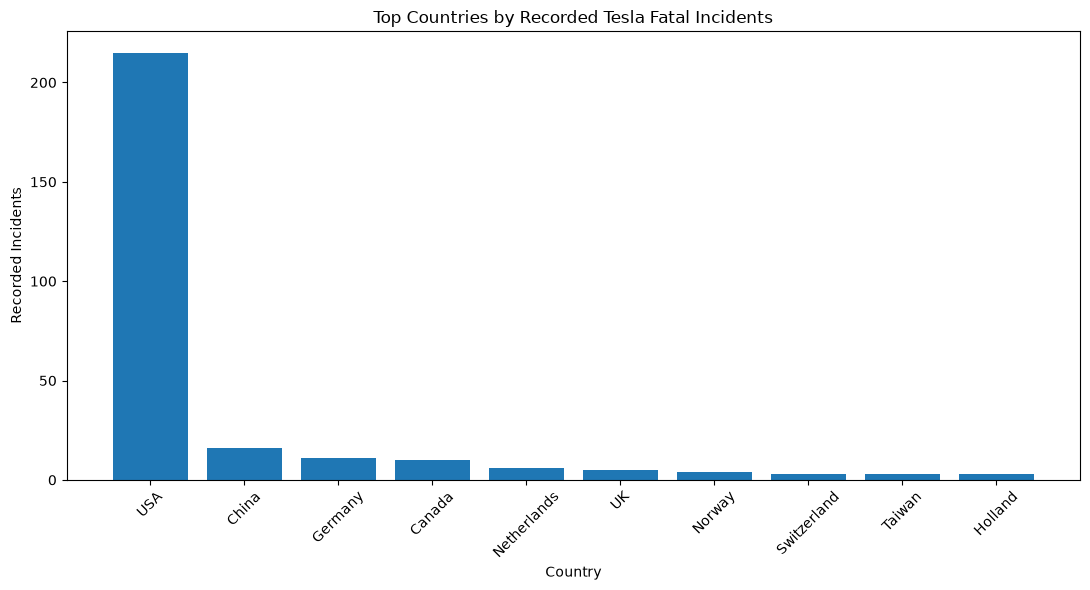

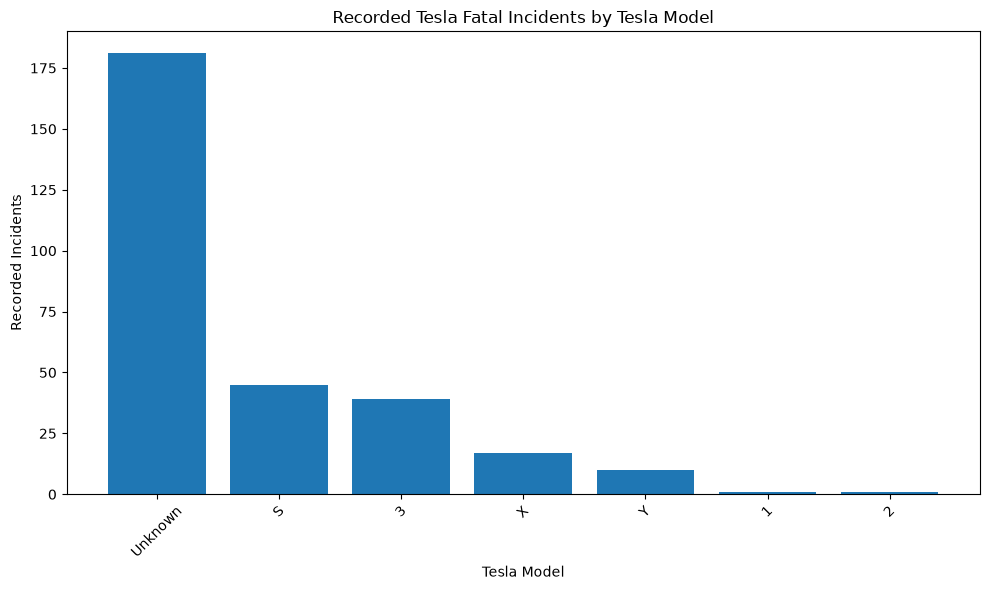

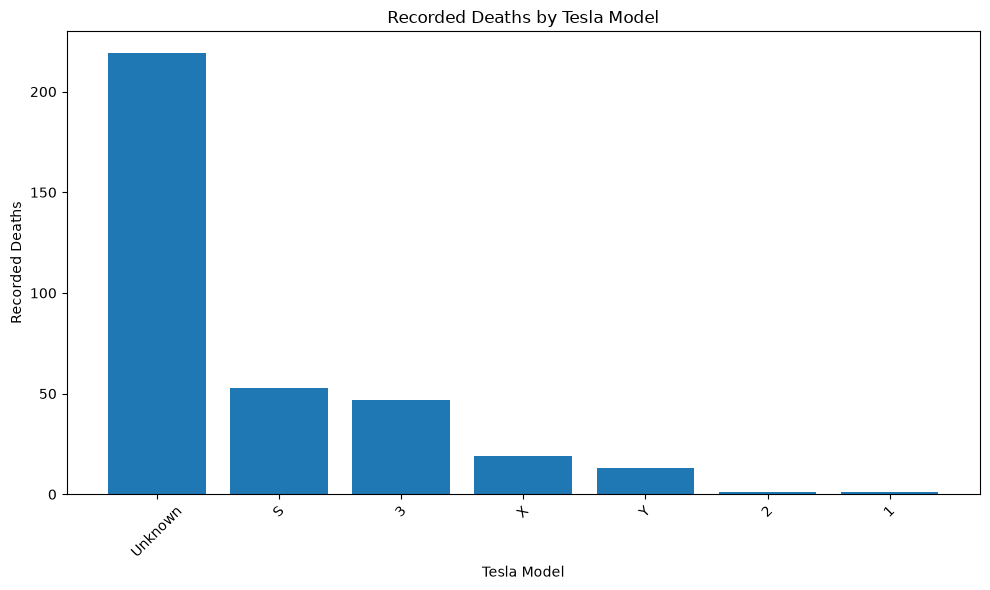

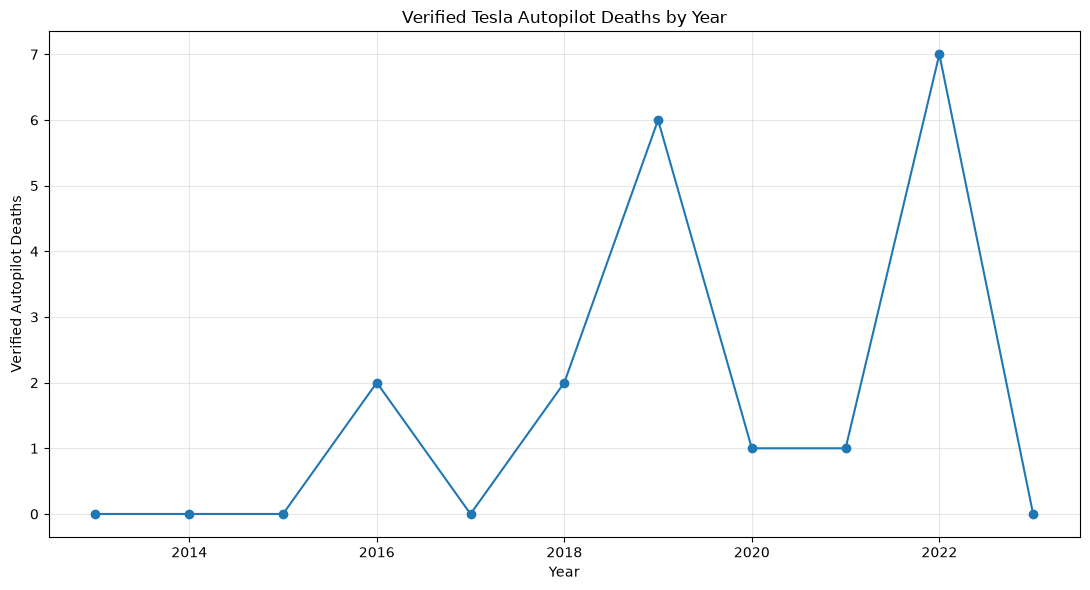

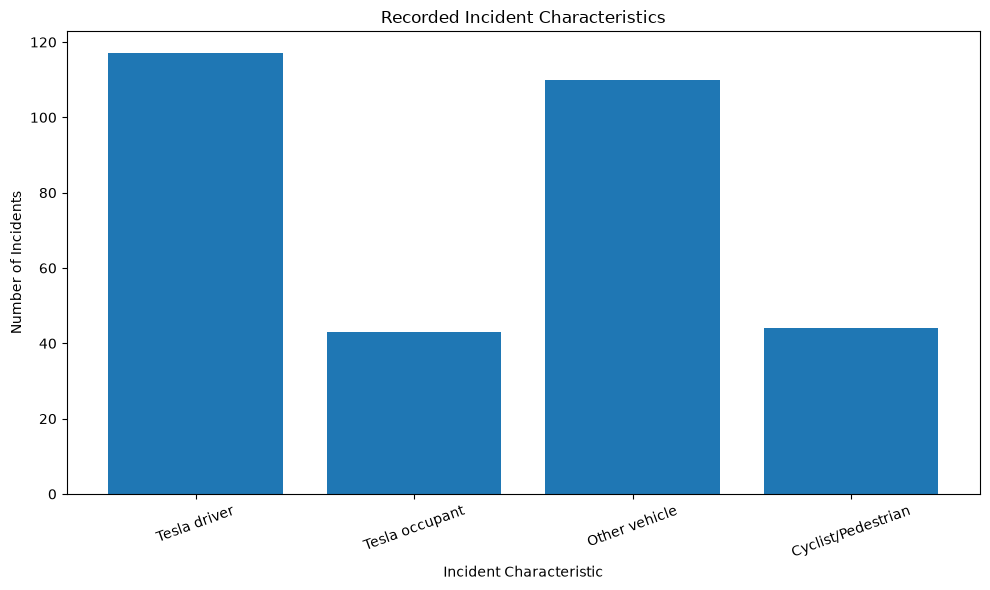


AUTOPILOT CLAIM VS VERIFIED AUTOPILOT DEATH


,No verified Autopilot death,Verified Autopilot death
No claim recorded,257,2
Claim recorded,21,14



REPORT-READY GEOGRAPHIC SUMMARY


,Country,Recorded_Incidents,Recorded_Deaths,Autopilot_Claims,Verified_Autopilot_Deaths
21,USA,215,261.0,27,16.0
4,China,16,20.0,2,1.0
8,Germany,11,16.0,2,0.0
3,Canada,10,12.0,0,0.0
12,Netherlands,6,6.0,0,0.0
20,UK,5,5.0,0,0.0
13,Norway,4,4.0,1,1.0
19,Taiwan,3,3.0,0,0.0
18,Switzerland,3,3.0,0,0.0
9,Holland,3,3.0,1,0.0



REPORT-READY INCIDENT CHARACTERISTICS


,Characteristic,Recorded_Incidents,Percentage_of_Incidents
0,Tesla driver,117,39.80
1,Tesla occupant,43,14.63
2,Other vehicle,110,37.41
3,Cyclist/Pedestrian,44,14.97
4,Autopilot claim,35,11.90
5,Verified Autopilot death,16,5.44



REPORT-READY INSIGHTS

Dataset scope:
The final analytical dataset contains 294 unique
recorded Tesla fatal incidents and 353 recorded
deaths.

Fatality distribution:
The dataset therefore contains an average of
1.20 recorded deaths per incident.

Autopilot documentation:
35 incidents contain an explicitly recorded
Autopilot claim, representing
11.90% of incidents.

Verified Autopilot deaths:
16 incidents contain verified
Autopilot-death records, representing
5.44%
of all incidents.

These verified records account for
19 deaths.

Geographic distribution:
The United States represents the largest geographic component
of the dataset, while incidents are also recorded across
multiple other countries.

Data completeness:
Important incident-characteristic fields contain missing values.
Therefore, recorded presence should be distinguished from
confirmed absence.

Model coverage:
A large number of records have an unknown Tesla model, limiting
the interpretation of model-level comparisons.

Te

In [140]:
# ============================================================
# PHASE 8 — FINAL VISUAL ANALYTICS & REPORT-READY TABLES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 8 — FINAL VISUAL ANALYTICS")
print("=" * 70)


# ============================================================
# 1. VERIFY FINAL DATAFRAME
# ============================================================

if "report_df" not in globals():

    if "final_df" in globals():
        report_df = final_df.copy()

    elif "analysis_df" in globals():
        report_df = analysis_df.copy()

    elif "working_df" in globals():
        report_df = working_df.copy()

    else:
        raise NameError(
            "No final dataframe found."
        )

print("\nFinal dataframe shape:", report_df.shape)

if "Case #" in report_df.columns:
    print(
        "Unique cases:",
        report_df["Case #"].nunique()
    )


# ============================================================
# 2. PREPARE FINAL ANALYTICAL VARIABLES
# ============================================================

visual_df = report_df.copy()

# Date
if "Date" in visual_df.columns:

    visual_df["Date"] = pd.to_datetime(
        visual_df["Date"],
        errors="coerce"
    )

    visual_df["Event_Year"] = (
        visual_df["Date"].dt.year
    )


# Deaths
visual_df["Deaths_numeric"] = pd.to_numeric(
    visual_df["Deaths"],
    errors="coerce"
).fillna(0)


# Autopilot claim
if "Autopilot claimed" in visual_df.columns:

    visual_df["_autopilot_claim"] = (
        visual_df["Autopilot claimed"]
        .notna()
        .astype(int)
    )

else:

    visual_df["_autopilot_claim"] = 0


# Verified Autopilot deaths
if "Verified Tesla Autopilot Deaths_count" in visual_df.columns:

    visual_df["_verified_autopilot_deaths"] = (
        pd.to_numeric(
            visual_df[
                "Verified Tesla Autopilot Deaths_count"
            ],
            errors="coerce"
        )
        .fillna(0)
    )

elif "Verified Tesla Autopilot Deaths" in visual_df.columns:

    visual_df["_verified_autopilot_deaths"] = (
        pd.to_numeric(
            visual_df[
                "Verified Tesla Autopilot Deaths"
            ],
            errors="coerce"
        )
        .fillna(0)
    )

else:

    visual_df["_verified_autopilot_deaths"] = 0


# Incident-level verified Autopilot indicator
visual_df["_verified_autopilot_incident"] = (
    visual_df["_verified_autopilot_deaths"] > 0
).astype(int)


# ============================================================
# 3. FINAL KPI SUMMARY
# ============================================================

total_incidents = len(visual_df)

total_deaths = visual_df[
    "Deaths_numeric"
].sum()

autopilot_claims = visual_df[
    "_autopilot_claim"
].sum()

verified_autopilot_incidents = visual_df[
    "_verified_autopilot_incident"
].sum()

verified_autopilot_deaths = visual_df[
    "_verified_autopilot_deaths"
].sum()

kpi_table = pd.DataFrame({

    "Metric": [
        "Total incidents",
        "Total recorded deaths",
        "Average deaths per incident",
        "Autopilot claim incidents",
        "Verified Autopilot-death incidents",
        "Verified Autopilot deaths"
    ],

    "Value": [
        total_incidents,
        total_deaths,
        total_deaths / total_incidents,
        autopilot_claims,
        verified_autopilot_incidents,
        verified_autopilot_deaths
    ]
})

print("\n" + "=" * 70)
print("FINAL KPI TABLE")
print("=" * 70)

display(
    kpi_table.round(2)
)


# ============================================================
# 4. FIGURE 1 — INCIDENTS BY COUNTRY
# ============================================================

if "Country" in visual_df.columns:

    country_counts = (
        visual_df["Country"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
        .value_counts()
        .head(10)
    )

    plt.figure(figsize=(11, 6))

    plt.bar(
        country_counts.index,
        country_counts.values
    )

    plt.title(
        "Top Countries by Recorded Tesla Fatal Incidents"
    )

    plt.xlabel("Country")
    plt.ylabel("Recorded Incidents")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. FIGURE 2 — INCIDENTS BY TESLA MODEL
# ============================================================

if "Model" in visual_df.columns:

    model_counts = (
        visual_df["Model"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
        .value_counts()
    )

    plt.figure(figsize=(10, 6))

    plt.bar(
        model_counts.index,
        model_counts.values
    )

    plt.title(
        "Recorded Tesla Fatal Incidents by Tesla Model"
    )

    plt.xlabel("Tesla Model")
    plt.ylabel("Recorded Incidents")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


# ============================================================
# 6. FIGURE 3 — TOTAL DEATHS BY TESLA MODEL
# ============================================================

if "Model" in visual_df.columns:

    model_deaths = (
        visual_df
        .groupby(
            visual_df["Model"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )["Deaths_numeric"]
        .sum()
        .sort_values(
            ascending=False
        )
    )

    plt.figure(figsize=(10, 6))

    plt.bar(
        model_deaths.index,
        model_deaths.values
    )

    plt.title(
        "Recorded Deaths by Tesla Model"
    )

    plt.xlabel("Tesla Model")
    plt.ylabel("Recorded Deaths")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


# ============================================================
# 7. FIGURE 4 — VERIFIED AUTOPILOT DEATHS BY YEAR
# ============================================================

if "Event_Year" in visual_df.columns:

    yearly_autopilot = (
        visual_df
        .groupby("Event_Year")[
            "_verified_autopilot_deaths"
        ]
        .sum()
        .sort_index()
    )

    plt.figure(figsize=(11, 6))

    plt.plot(
        yearly_autopilot.index,
        yearly_autopilot.values,
        marker="o"
    )

    plt.title(
        "Verified Tesla Autopilot Deaths by Year"
    )

    plt.xlabel("Year")
    plt.ylabel("Verified Autopilot Deaths")

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 8. FIGURE 5 — INCIDENT CHARACTERISTICS
# ============================================================

characteristics = {}

if "Tesla driver" in visual_df.columns:
    characteristics[
        "Tesla driver"
    ] = visual_df["Tesla driver"].notna().sum()

if "Tesla occupant" in visual_df.columns:
    characteristics[
        "Tesla occupant"
    ] = visual_df["Tesla occupant"].notna().sum()

if "Other vehicle" in visual_df.columns:
    characteristics[
        "Other vehicle"
    ] = visual_df["Other vehicle"].notna().sum()

if "Cyclists/ Peds" in visual_df.columns:
    characteristics[
        "Cyclist/Pedestrian"
    ] = visual_df["Cyclists/ Peds"].notna().sum()


characteristic_series = pd.Series(
    characteristics
)

plt.figure(figsize=(10, 6))

plt.bar(
    characteristic_series.index,
    characteristic_series.values
)

plt.title(
    "Recorded Incident Characteristics"
)

plt.xlabel("Incident Characteristic")
plt.ylabel("Number of Incidents")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


# ============================================================
# 9. FIGURE 6 — AUTOPILOT CLAIM VS VERIFIED DEATH
# ============================================================

autopilot_crosstab = pd.crosstab(
    visual_df["_autopilot_claim"],
    visual_df["_verified_autopilot_incident"]
)

autopilot_crosstab.index = [
    "No claim recorded",
    "Claim recorded"
]

autopilot_crosstab.columns = [
    "No verified Autopilot death",
    "Verified Autopilot death"
]

print("\n" + "=" * 70)
print("AUTOPILOT CLAIM VS VERIFIED AUTOPILOT DEATH")
print("=" * 70)

display(autopilot_crosstab)


# ============================================================
# 10. REPORT-READY GEOGRAPHIC TABLE
# ============================================================

if "Country" in visual_df.columns:

    geographic_table = (
        visual_df
        .assign(
            Country_clean=
            visual_df["Country"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )
        .groupby("Country_clean")
        .agg(
            Recorded_Incidents=(
                "Deaths_numeric",
                "size"
            ),
            Recorded_Deaths=(
                "Deaths_numeric",
                "sum"
            ),
            Autopilot_Claims=(
                "_autopilot_claim",
                "sum"
            ),
            Verified_Autopilot_Deaths=(
                "_verified_autopilot_deaths",
                "sum"
            )
        )
        .reset_index()
        .rename(
            columns={
                "Country_clean": "Country"
            }
        )
        .sort_values(
            "Recorded_Incidents",
            ascending=False
        )
    )

    print("\n" + "=" * 70)
    print("REPORT-READY GEOGRAPHIC SUMMARY")
    print("=" * 70)

    display(
        geographic_table.head(15)
    )


# ============================================================
# 11. REPORT-READY INCIDENT CHARACTERISTICS TABLE
# ============================================================

report_characteristics = pd.DataFrame({

    "Characteristic": [
        "Tesla driver",
        "Tesla occupant",
        "Other vehicle",
        "Cyclist/Pedestrian",
        "Autopilot claim",
        "Verified Autopilot death"
    ],

    "Recorded_Incidents": [

        visual_df["Tesla driver"].notna().sum()
        if "Tesla driver" in visual_df.columns
        else np.nan,

        visual_df["Tesla occupant"].notna().sum()
        if "Tesla occupant" in visual_df.columns
        else np.nan,

        visual_df["Other vehicle"].notna().sum()
        if "Other vehicle" in visual_df.columns
        else np.nan,

        visual_df["Cyclists/ Peds"].notna().sum()
        if "Cyclists/ Peds" in visual_df.columns
        else np.nan,

        autopilot_claims,

        verified_autopilot_incidents
    ]
})

report_characteristics[
    "Percentage_of_Incidents"
] = (
    report_characteristics[
        "Recorded_Incidents"
    ]
    / total_incidents
    * 100
)

print("\n" + "=" * 70)
print("REPORT-READY INCIDENT CHARACTERISTICS")
print("=" * 70)

display(
    report_characteristics.round(2)
)


# ============================================================
# 12. FINAL REPORT INSIGHTS
# ============================================================

print("\n" + "=" * 70)
print("REPORT-READY INSIGHTS")
print("=" * 70)

print(
    f"""
Dataset scope:
The final analytical dataset contains {total_incidents} unique
recorded Tesla fatal incidents and {total_deaths:.0f} recorded
deaths.

Fatality distribution:
The dataset therefore contains an average of
{total_deaths / total_incidents:.2f} recorded deaths per incident.

Autopilot documentation:
{autopilot_claims} incidents contain an explicitly recorded
Autopilot claim, representing
{(autopilot_claims / total_incidents) * 100:.2f}% of incidents.

Verified Autopilot deaths:
{verified_autopilot_incidents} incidents contain verified
Autopilot-death records, representing
{(verified_autopilot_incidents / total_incidents) * 100:.2f}%
of all incidents.

These verified records account for
{verified_autopilot_deaths:.0f} deaths.

Geographic distribution:
The United States represents the largest geographic component
of the dataset, while incidents are also recorded across
multiple other countries.

Data completeness:
Important incident-characteristic fields contain missing values.
Therefore, recorded presence should be distinguished from
confirmed absence.

Model coverage:
A large number of records have an unknown Tesla model, limiting
the interpretation of model-level comparisons.

Temporal analysis:
Verified Autopilot deaths are distributed unevenly across the
2013–2023 period, with the highest recorded annual values in
2019 and 2022 within this dataset.

Interpretation:
These results describe the recorded dataset and should not be
interpreted as population-level Tesla or Autopilot fatality
rates because consistent exposure denominators are unavailable.
"""
)


# ============================================================
# 13. PHASE 8 COMPLETE
# ============================================================

print("\n" + "=" * 70)
print("PHASE 8 COMPLETE")
print("=" * 70)

print(
    "Final analytical dataset:",
    visual_df.shape
)

print(
    "Unique cases:",
    visual_df["Case #"].nunique()
    if "Case #" in visual_df.columns
    else "N/A"
)

print(
    "Total deaths:",
    total_deaths
)

print(
    "Autopilot claims:",
    autopilot_claims
)

print(
    "Verified Autopilot-death incidents:",
    verified_autopilot_incidents
)

print(
    "Verified Autopilot deaths:",
    verified_autopilot_deaths
)

print("=" * 70)